# 📊 Análisis Exploratorio de Datos (EDA) - Dataset Base OTC
### Diagnóstico Integral de Calidad de Datos, Capital Humano, Matriz de Habilidades, Compensaciones, Asignaciones y Activos

---

## 📌 Contexto Ejecutivo y Objetivos
El presente Notebook desarrolla una auditoría profunda y un **análisis exploratorio exhaustivo (EDA)** sobre el archivo maestro `DATASET_BASE_OTC.xlsx`.

Este análisis busca responder preguntas de negocio sobre la consultora:
1. **Gobernanza y Calidad del Dato:** Nulos, campos marcados como `PENDIENTE`, fechas placeholder (`1990-01-01`) y registros financieros en `$0`.
2. **Integridad Referencial Multi-Hoja:** Cruce de colaboradores en *Colaboradores*, *Sueldos_Salarios*, *Matriz Habilidades* y *Asignaciones_Colaboradores*.
3. **Capacidades Técnicas:** Mapeo de la matriz de habilidades (escala numérica 1 a 4), concentración de conocimiento y brechas de talento experto.
4. **Madurez Tecnológica:** Comparativa directa del nivel de dominio entre plataformas legadas (*Oracle eBS*) y plataformas modernas (*Oracle Fusion Cloud*).
5. **Estructura Salarial y Riesgo Fiscal:** Dispersión por puesto/nivel, traslapes salariales y composición de nómina (IMSS vs. Sindicato/Asimilados vs. Complementos).
6. **Compensación por Competencias:** Correlación entre versatilidad técnica (habilidades Avanzado/Experto) y sueldo neto percibido.
7. **Eficiencia Operativa:** Proporción de consultores asignados vs. consultores en **Banca**, y el impacto financiero del costo integrado de la banca.
8. **Concentración de Negocio:** Análisis de Pareto sobre clientes, proyectos y concentración de costo de nómina.
9. **Dinámica de Personal:** Evolución histórica de altas, bajas y cálculo de la tasa de rotación anual (*turnover rate*).
10. **Control de Activos de TI:** Valoración de inventario, equipos asignados a colaboradores dados de baja y consultores activos sin equipo computacional.

---


## ⚙️ Configuración del Entorno y Carga de Datos
Importamos las librerías analíticas fundamentales (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `upsetplot`) y establecemos una paleta estética uniforme y profesional.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from scipy import stats
import upsetplot
from IPython.display import display, HTML, Markdown

warnings.filterwarnings('ignore')

# Estilo gráfico corporativo
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#E2E8F0'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7

# Paleta de colores OTC
PALETTE_OTC = ['#1E3A8A', '#0D9488', '#F59E0B', '#EF4444', '#6366F1', '#8B5CF6', '#10B981']

# Archivo de datos
EXCEL_PATH = 'DATASET_BASE_OTC.xlsx'
xl = pd.ExcelFile(EXCEL_PATH)

print(f"✅ Conexión exitosa a '{EXCEL_PATH}'")
print(f"📋 Total de hojas detectadas ({len(xl.sheet_names)}): {xl.sheet_names}")

# Carga de las hojas principales en memoria
df_colab = xl.parse('Colaboradores')
df_sueldos = xl.parse('Sueldos_Salarios')
df_matriz = xl.parse('Matriz Habilidades')
df_asig = xl.parse('Asignaciones_Colaboradores')
df_activos = xl.parse('Inventario_Activos')
df_clientes = xl.parse('Clientes_Proyectos')
df_hab = xl.parse('Habilidades')
df_roles = xl.parse('Roles')
df_deptos = xl.parse('Departamentos')

print(f"📊 Colaboradores: {df_colab.shape[0]} filas | Sueldos: {df_sueldos.shape[0]} filas | Matriz: {df_matriz.shape[0]} filas | Asignaciones: {df_asig.shape[0]} filas | Activos: {df_activos.shape[0]} filas")


✅ Conexión exitosa a 'DATASET_BASE_OTC.xlsx'
📋 Total de hojas detectadas (10): ['Sheet1', 'Asignaciones_Colaboradores', 'Inventario_Activos', 'Clientes_Proyectos', 'Colaboradores', 'Departamentos', 'Habilidades', 'Roles', 'Matriz Habilidades', 'Sueldos_Salarios']
📊 Colaboradores: 107 filas | Sueldos: 75 filas | Matriz: 54 filas | Asignaciones: 31 filas | Activos: 123 filas


---
## 1️⃣ Tabla de Calidad de Datos
### Detección de Nulos, "PENDIENTE", Fechas de Relleno (`1990-01-01`) y Costos en `$0`

#### Justificación Metodológica:
La confiabilidad de un análisis organizacional depende de la limpieza de sus fuentes. En este apartado auditamos exhaustivamente todas las columnas de cada hoja para identificar:
1. **Valores Nulos / NaN:** Ausencia absoluta de información.
2. **Textos de Marcado "PENDIENTE":** Datos no capturados formalmente en el sistema de origen.
3. **Fechas Placeholder ("1990-01-01"):** Valores por defecto generados por sistemas ERP/Legacy ante la ausencia de una fecha real.
4. **Costos / Sueldos en $0:** Registros monetarios en cero que distorsionan los promedios financieros y reflejan omisiones contables.


In [2]:
def auditar_calidad_datos(excel_file):
    calidad_records = []
    
    for sheet_name in excel_file.sheet_names:
        if sheet_name == 'Sheet1':
            continue  # Hoja vacía
        
        df = excel_file.parse(sheet_name)
        total_filas = len(df)
        
        if total_filas == 0:
            continue
            
        for col in df.columns:
            serie = df[col]
            
            # 1. Nulos
            n_nulos = serie.isna().sum()
            
            # 2. Textos 'PENDIENTE'
            s_str = serie.astype(str).str.strip().str.upper()
            n_pendiente = (s_str == 'PENDIENTE').sum()
            
            # 3. Fechas de relleno (1990-01-01)
            n_1990 = s_str.str.startswith('1990-01-01').sum()
            
            # 4. Costos o valores en 0
            n_ceros = 0
            if pd.api.types.is_numeric_dtype(serie):
                n_ceros = (serie == 0).sum()
            elif serie.dtype == 'object':
                n_ceros = s_str.isin(['0', '0.0', '$0', '$0.00', '0.00']).sum()
            
            total_anomalias = n_nulos + n_pendiente + n_1990 + n_ceros
            pct_anomalias = (total_anomalias / total_filas) * 100
            
            calidad_records.append({
                'Hoja': sheet_name,
                'Columna': col,
                'Total Registros': total_filas,
                'Nulos (NaN)': n_nulos,
                '"PENDIENTE"': n_pendiente,
                'Fecha 1990-01-01': n_1990,
                'Valores en 0': n_ceros,
                'Total Anomalías': total_anomalias,
                '% Afectado': round(pct_anomalias, 2)
            })
            
    return pd.DataFrame(calidad_records)

df_calidad = auditar_calidad_datos(xl)

# Resumen a nivel Hoja
resumen_hojas = df_calidad.groupby('Hoja').agg(
    Columnas_Totales=('Columna', 'count'),
    Columnas_Con_Anomalias=('Total Anomalías', lambda x: (x > 0).sum()),
    Total_Celdas_Anomalas=('Total Anomalías', 'sum'),
    Pct_Promedio_Afectacion=('% Afectado', 'mean')
).reset_index().sort_values(by='Total_Celdas_Anomalas', ascending=False)

display(Markdown("### 📋 Resumen de Calidad por Hoja del Dataset"))
display(resumen_hojas)

# Mostrar las 25 columnas más críticas del dataset
display(Markdown("### ⚠️ Top 25 Columnas con Mayor Cantidad de Anomalías y Datos Incompletos"))
top_anomalias = df_calidad[df_calidad['Total Anomalías'] > 0].sort_values(by=['Total Anomalías', '% Afectado'], ascending=False).head(25)
display(top_anomalias.reset_index(drop=True))


### 📋 Resumen de Calidad por Hoja del Dataset

,Hoja,Columnas_Totales,Columnas_Con_Anomalias,Total_Celdas_Anomalas,Pct_Promedio_Afectacion
6,Matriz Habilidades,77,72,2384,57.334675
2,Colaboradores,45,32,1700,35.306000
5,Inventario_Activos,11,5,171,12.638182
8,Sueldos_Salarios,8,4,103,17.167500
0,Asignaciones_Colaboradores,11,3,64,18.768182
1,Clientes_Proyectos,13,6,38,24.359231
3,Departamentos,7,2,12,28.571429
7,Roles,6,3,4,1.213333
4,Habilidades,6,0,0,0.000000


### ⚠️ Top 25 Columnas con Mayor Cantidad de Anomalías y Datos Incompletos

,Hoja,Columna,Total Registros,Nulos (NaN),"""PENDIENTE""",Fecha 1990-01-01,Valores en 0,Total Anomalías,% Afectado
0,Colaboradores,Alergias/Condiciones,107,3,104,0,0,107,100.00
1,Colaboradores,Notas,107,107,0,0,0,107,100.00
2,Colaboradores,Porcentaje Beneficiario,107,104,0,0,0,104,97.20
3,Colaboradores,Beneficiario,107,3,98,0,0,101,94.39
4,Colaboradores,Parentesco,107,3,98,0,0,101,94.39
5,Colaboradores,Sueldo Complementos,107,0,0,0,97,97,90.65
6,Colaboradores,Aviso: Manutención,107,0,97,0,0,97,90.65
7,Colaboradores,Departamento,107,95,0,0,0,95,88.79
8,Colaboradores,Aviso: Infonavit,107,0,95,0,0,95,88.79
9,Colaboradores,Fecha de Baja,107,92,0,0,0,92,85.98


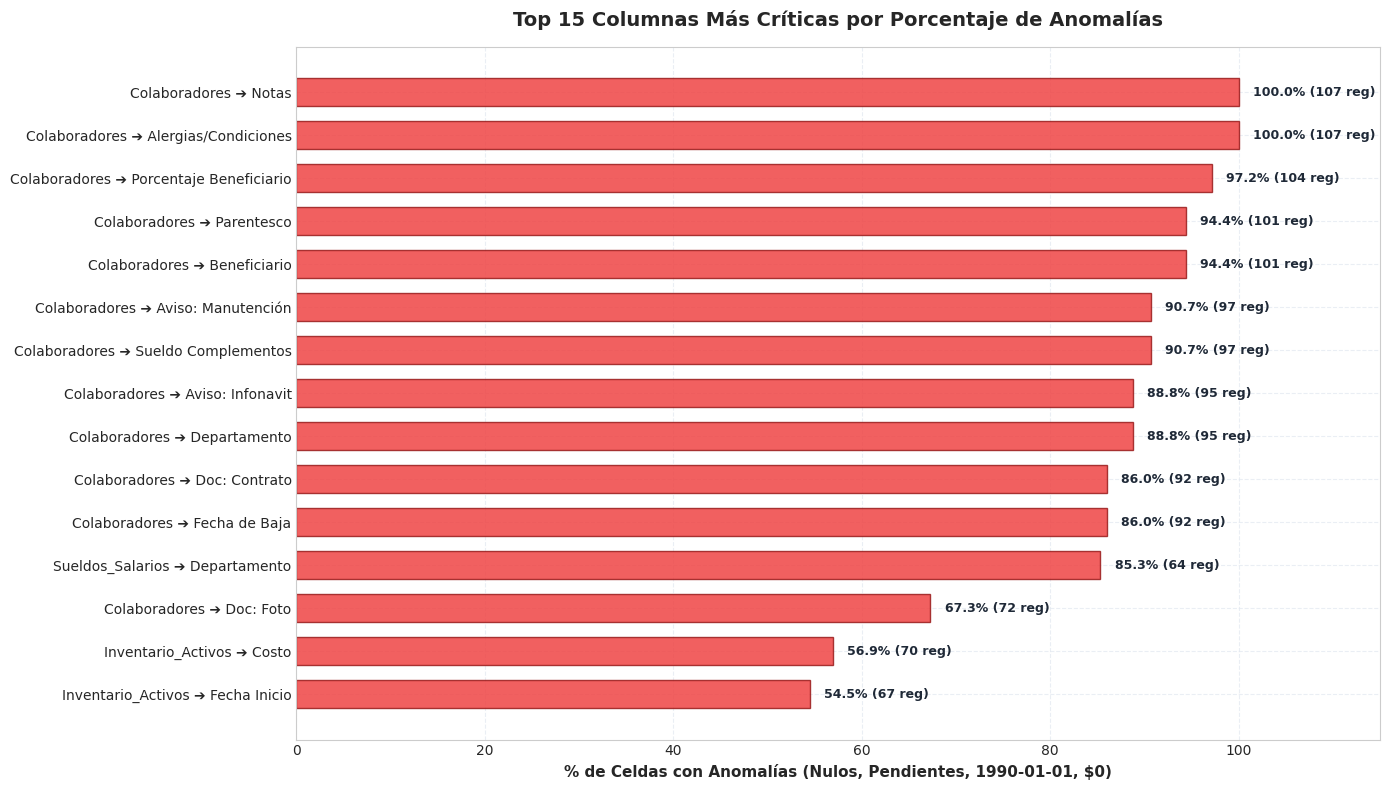

In [3]:
# Visualización gráfica de las columnas más comprometidas
plt.figure(figsize=(14, 8))
top_plot = top_anomalias.head(15).sort_values(by='% Afectado', ascending=True)

y_pos = range(len(top_plot))
plt.barh(y_pos, top_plot['% Afectado'], color='#EF4444', alpha=0.85, edgecolor='#991B1B', height=0.65)
plt.yticks(y_pos, [f"{h} ➔ {c[:28]}" for h, c in zip(top_plot['Hoja'], top_plot['Columna'])], fontsize=10)
plt.xlabel('% de Celdas con Anomalías (Nulos, Pendientes, 1990-01-01, $0)', fontsize=11, fontweight='bold')
plt.title('Top 15 Columnas Más Críticas por Porcentaje de Anomalías', fontsize=14, fontweight='bold', pad=15)
plt.xlim(0, 115)

for i, v in enumerate(top_plot['% Afectado']):
    plt.text(v + 1.5, i, f"{v:.1f}% ({top_plot.iloc[i]['Total Anomalías']} reg)", va='center', fontsize=9, fontweight='bold', color='#1F2937')

plt.tight_layout()
plt.show()


#### 💡 Hallazgos Críticos de Calidad de Datos:
* **Matriz de Habilidades Incompleta:** Las columnas de Soft Skills (`S0004 - Empatia`, `S0005 - Manejo de Conflictos`) presentan **100% de nulos** (54/54), denotando que el módulo de habilidades blandas nunca fue alimentado.
* **Falta de Estandarización de Puestos:** 48 colaboradores en *Colaboradores* y 29 en *Sueldos_Salarios* tienen su puesto registrado literalmente como `PENDIENTE`.
* **Uso de Fechas Placeholder:** En *Asignaciones* hay **21 registros con `1990-01-01`**, y en *Inventario_Activos* hay **35 registros** con esta misma fecha, lo que imposibilita calcular antigüedades o duraciones reales sin limpieza previa.
* **Omisión de Costos en Inventario:** De los 123 activos computacionales registrados, **70 activos tienen Costo = $0.00**, lo que subestima enormemente el valor contable del inventario.


---
## 2️⃣ Diagrama UpSet / Venn de Integridad entre Hojas
### Trazabilidad de Colaboradores en: *Colaboradores*, *Sueldos_Salarios*, *Matriz Habilidades* y *Asignaciones_Colaboradores*

#### Justificación Metodológica:
Una organización integrada requiere que cada persona registrada en nómina cuente con expediente de colaborador, matriz de competencias y asignación a proyecto o banca. 
El diagrama UpSet es la herramienta idónea (superior a un diagrama de Venn de 4 conjuntos) para visualizar intersecciones y detectar registros huérfanos o ausencias sistemáticas entre módulos.


In [4]:
# Extracción limpia de identificadores únicos
id_colab = set(df_colab['ID'].dropna().astype(str).str.strip().unique())
id_sueldos = set(df_sueldos['ID'].dropna().astype(str).str.strip().unique())
id_matriz = set(df_matriz['ID Colaborador'].dropna().astype(str).str.strip().unique())
id_asig = set(df_asig['ID Colaborador'].dropna().astype(str).str.strip().unique())

all_collaborator_ids = sorted(list(id_colab | id_sueldos | id_matriz | id_asig))

df_integrity = pd.DataFrame({'ID': all_collaborator_ids})
df_integrity['Colaboradores'] = df_integrity['ID'].isin(id_colab)
df_integrity['Sueldos'] = df_integrity['ID'].isin(id_sueldos)
df_integrity['Matriz Habilidades'] = df_integrity['ID'].isin(id_matriz)
df_integrity['Asignaciones'] = df_integrity['ID'].isin(id_asig)

# Conteo de combinaciones
grouped_integrity = df_integrity.groupby(
    ['Colaboradores', 'Sueldos', 'Matriz Habilidades', 'Asignaciones']
).size()

print("="*65)
print("RESUMEN DE COBERTURA POR HOJA:")
print(f"  • Total IDs Únicos en el ecosistema: {len(all_collaborator_ids)}")
print(f"  • Presentes en 'Colaboradores':       {len(id_colab)} ({len(id_colab)/len(all_collaborator_ids):.1%})")
print(f"  • Presentes en 'Sueldos_Salarios':    {len(id_sueldos)} ({len(id_sueldos)/len(all_collaborator_ids):.1%})")
print(f"  • Presentes en 'Matriz Habilidades':  {len(id_matriz)} ({len(id_matriz)/len(all_collaborator_ids):.1%})")
print(f"  • Presentes en 'Asignaciones':        {len(id_asig)} ({len(id_asig)/len(all_collaborator_ids):.1%})")
print("="*65)


RESUMEN DE COBERTURA POR HOJA:
  • Total IDs Únicos en el ecosistema: 107
  • Presentes en 'Colaboradores':       107 (100.0%)
  • Presentes en 'Sueldos_Salarios':    75 (70.1%)
  • Presentes en 'Matriz Habilidades':  54 (50.5%)
  • Presentes en 'Asignaciones':        30 (28.0%)


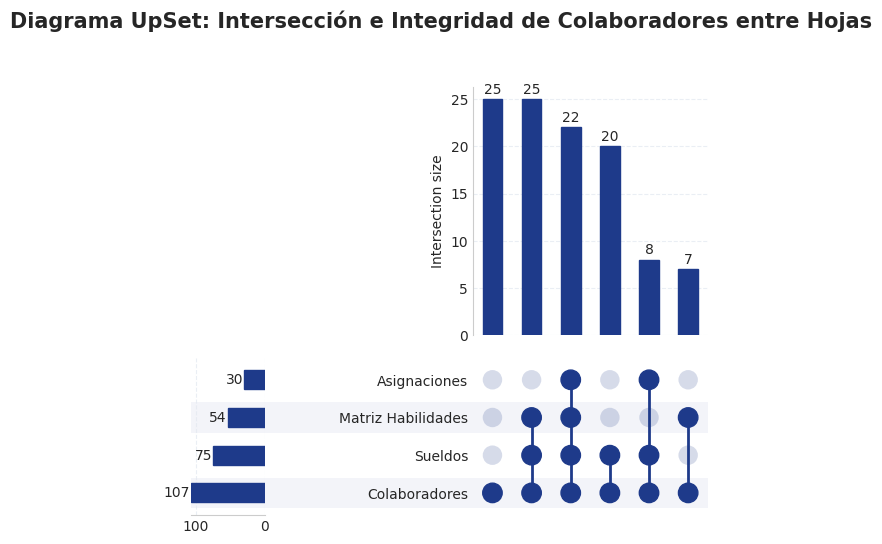

### 🧩 Desglose Exhaustivo de Intersecciones entre Hojas

,Combinación de Hojas,Colaboradores (N),% del Total (107),Interpretación de Negocio
0,Colaboradores,25,23.36,Colaboradores dados de BAJA o expedientes inac...
1,Colaboradores + Sueldos + Matriz,25,23.36,"Personal activo en nómina y evaluado, en BANCA..."
2,Colaboradores + Sueldos + Matriz + Asignaciones,22,20.56,"Perfil completo (En nómina, evaluado y asignado)"
3,Colaboradores + Sueldos,20,18.69,Personal con sueldo pero SIN matriz de habilid...
4,Colaboradores + Sueldos + Asignaciones,8,7.48,Colaborador asignado pero SIN evaluación en Ma...
5,Colaboradores + Matriz,7,6.54,Colaboradores dados de BAJA o expedientes inac...


In [5]:
# Generación del Diagrama UpSet
fig = plt.figure(figsize=(13, 7))
upset_plot = upsetplot.plot(
    grouped_integrity,
    fig=fig,
    sort_by='cardinality',
    show_counts=True,
    facecolor='#1E3A8A',
    element_size=40
)
plt.suptitle('Diagrama UpSet: Intersección e Integridad de Colaboradores entre Hojas', fontsize=15, fontweight='bold', y=1.02)
plt.show()

# Tabla desglosada de subconjuntos
breakdown_list = []
for idx, count in grouped_integrity.items():
    c_colab, c_sueldos, c_matriz, c_asig = idx
    sheets_present = []
    if c_colab: sheets_present.append("Colaboradores")
    if c_sueldos: sheets_present.append("Sueldos")
    if c_matriz: sheets_present.append("Matriz")
    if c_asig: sheets_present.append("Asignaciones")
    
    breakdown_list.append({
        'Combinación de Hojas': " + ".join(sheets_present),
        'Colaboradores (N)': count,
        '% del Total (107)': round((count / len(all_collaborator_ids)) * 100, 2),
        'Interpretación de Negocio': (
            "Perfil completo (En nómina, evaluado y asignado)" if len(sheets_present) == 4 else
            "Personal activo en nómina y evaluado, en BANCA (sin proyecto)" if (c_colab and c_sueldos and c_matriz and not c_asig) else
            "Personal con sueldo pero SIN matriz de habilidades (no asignado)" if (c_colab and c_sueldos and not c_matriz and not c_asig) else
            "Colaborador asignado pero SIN evaluación en Matriz" if (c_asig and not c_matriz) else
            "Colaboradores dados de BAJA o expedientes inactivos sin sueldo actual" if (c_colab and not c_sueldos) else
            "Otra discrepancia"
        )
    })

df_breakdown = pd.DataFrame(breakdown_list).sort_values(by='Colaboradores (N)', ascending=False)
display(Markdown("### 🧩 Desglose Exhaustivo de Intersecciones entre Hojas"))
display(df_breakdown.reset_index(drop=True))


#### 💡 Diagnóstico de Integridad Referencial:
1. **Solo 22 colaboradores (20.6%)** cuentan con registro completo en las 4 hojas simultáneamente (expediente, compensación, matriz técnica y asignación activa).
2. **32 personas registradas en *Colaboradores* no aparecen en *Sueldos_Salarios*:** Al cruzar con el estatus, se verifica que estas 32 personas corresponden exactamente al personal con estatus **Baja**, validando que la hoja de sueldos contiene únicamente colaboradores activos.
3. **53 colaboradores carecen de Matriz de Habilidades (49.5%):** OTC no tiene perfiladas las habilidades técnicas de la mitad de su plantilla.
4. **8 consultores tienen proyecto asignado pero NO están en la Matriz de Habilidades:** Existe riesgo operacional al asignar consultores a clientes sin una evaluación previa documentada de sus capacidades técnicas.


---
## 3️⃣ Heatmap de la Matriz de Habilidades
### Colaboradores vs. Módulos Técnicos (Niveles Cuantitativos del 1 al 4)

#### Justificación Metodológica:
La matriz cualitativa contiene los niveles: `Básico`, `Intermedio`, `Avanzado` y `Experto`. Para posibilitar el cálculo analítico y la visualización de alta densidad, convertimos esta escala a números enteros:
$$\text{Básico} \rightarrow 1 \quad | \quad \text{Intermedio} \rightarrow 2 \quad | \quad \text{Avanzado} \rightarrow 3 \quad | \quad \text{Experto} \rightarrow 4 \quad | \quad \text{Sin Evaluar} \rightarrow 0$$
Ordenamos tanto las filas (colaboradores) por su puntaje acumulado como las columnas (módulos) por familia tecnológica para revelar clústeres de especialización.


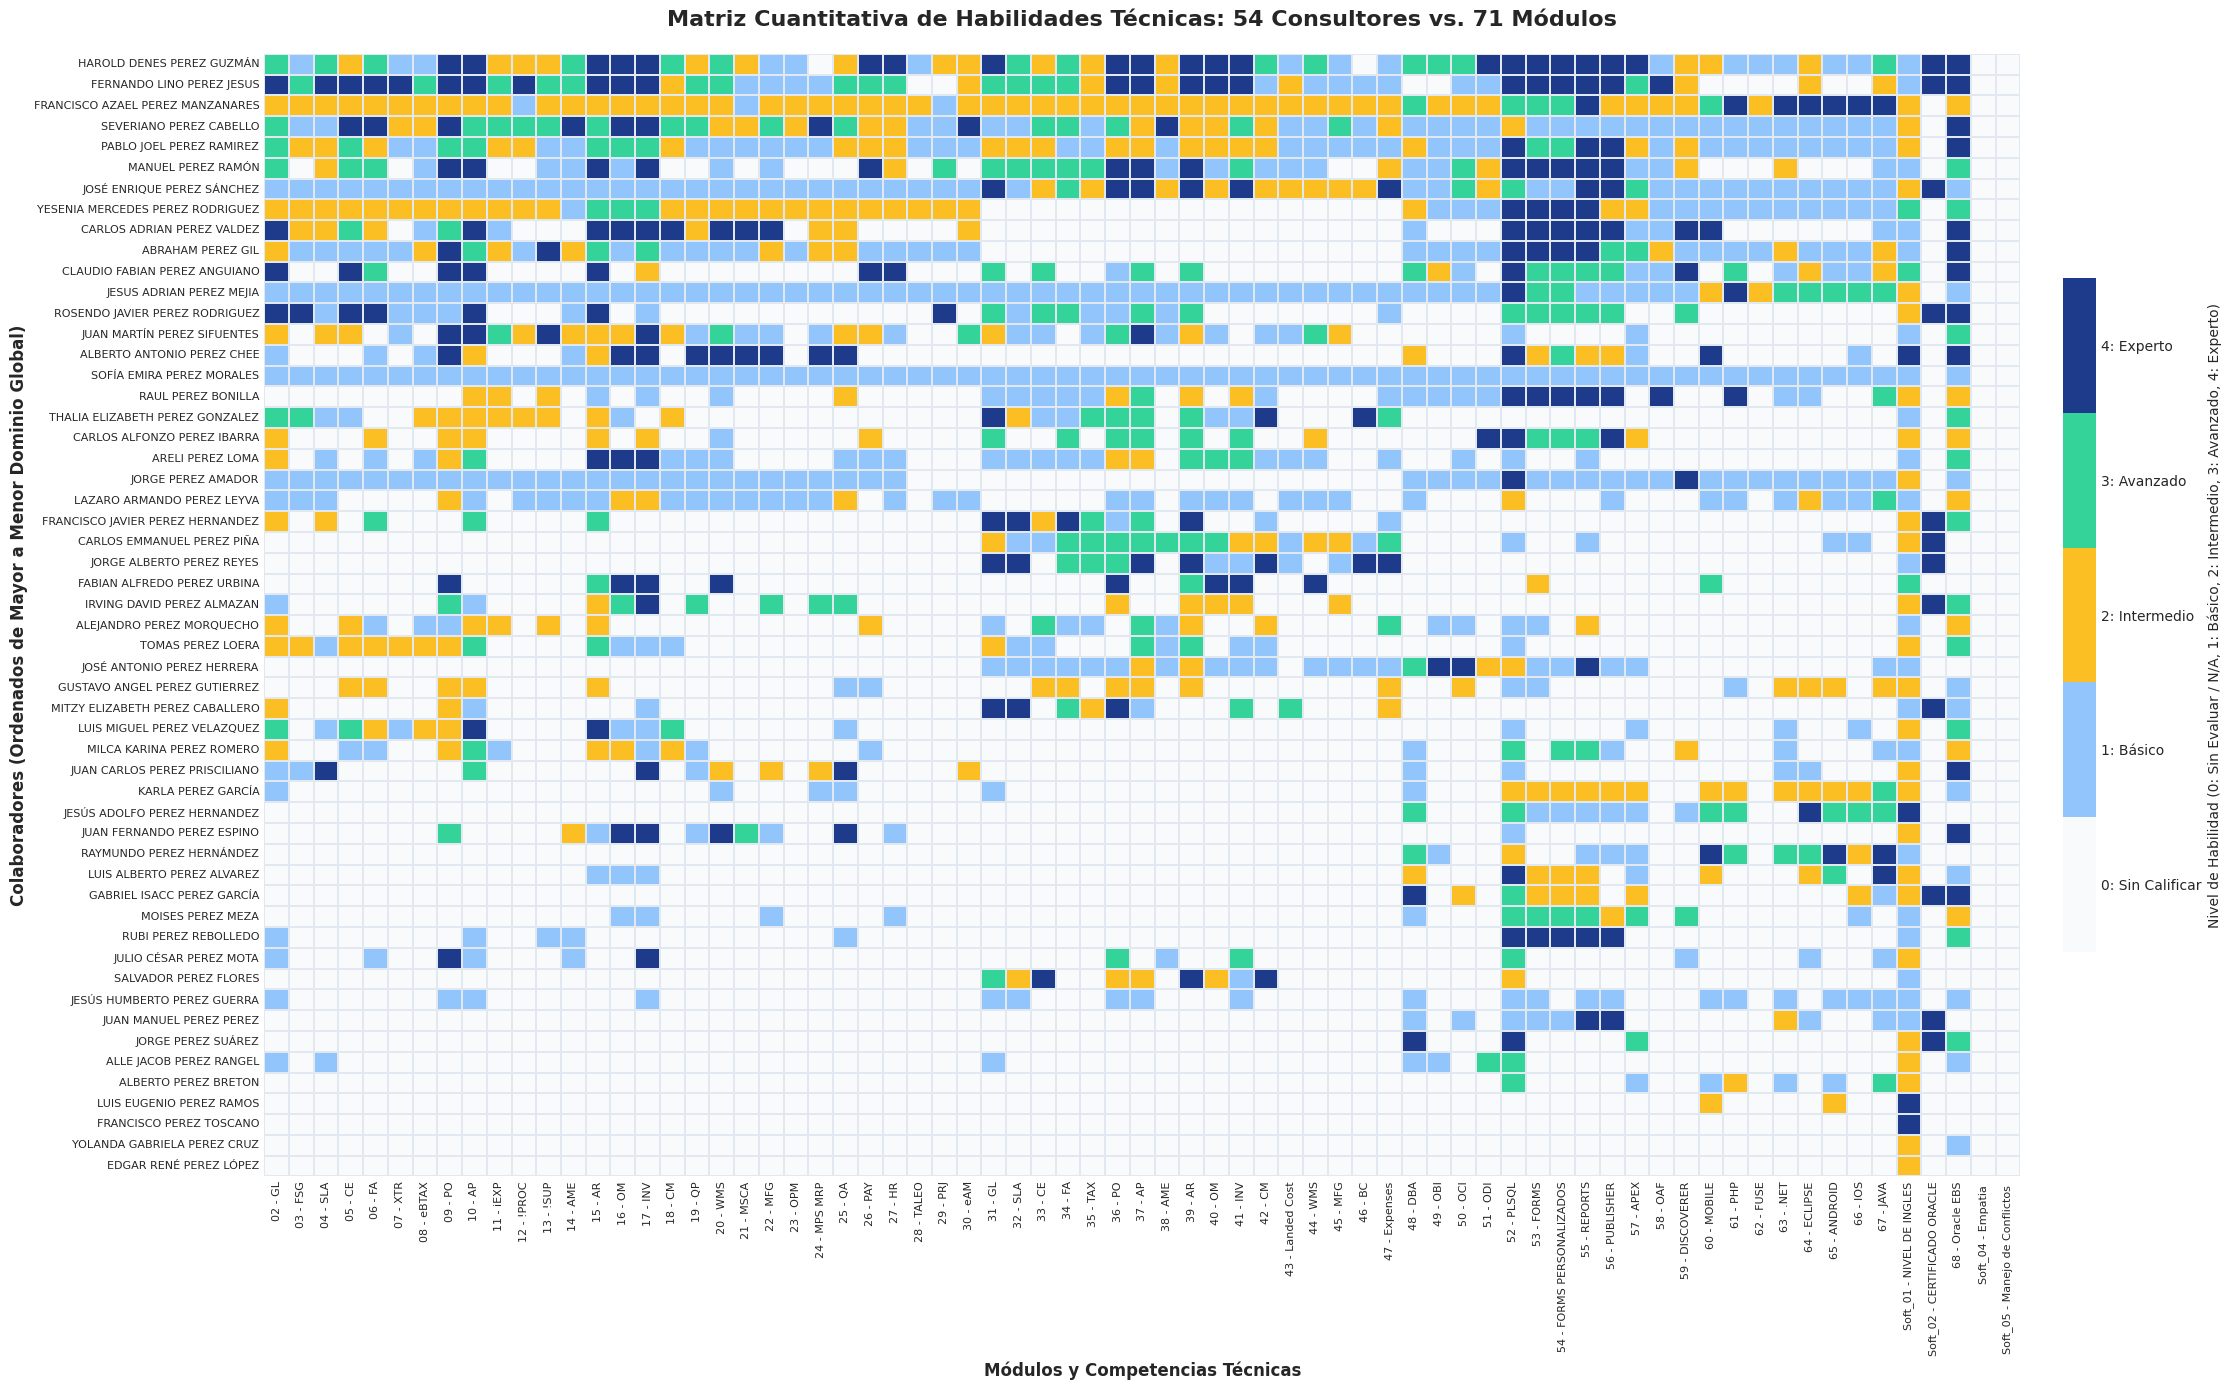

In [6]:
# Diccionario de homologación
MAP_NIVELES = {
    'Básico': 1,
    'Intermedio': 2,
    'Avanzado': 3,
    'Experto': 4
}

skill_cols = [c for c in df_matriz.columns if c.startswith('H0') or c.startswith('S0')]

# Creación de matriz numérica
df_matriz_num = df_matriz[['ID Colaborador', 'Nombre Completo']].copy()
for col in skill_cols:
    df_matriz_num[col] = df_matriz[col].map(MAP_NIVELES).fillna(0).astype(int)

# Cálculo de score total por colaborador para ordenar el heatmap
df_matriz_num['Total_Score'] = df_matriz_num[skill_cols].sum(axis=1)
df_matriz_num = df_matriz_num.sort_values(by='Total_Score', ascending=False)

# Configuración visual del heatmap
heatmap_data = df_matriz_num.set_index('Nombre Completo')[skill_cols]

# Limpiar nombres de columnas para que sean legibles (quitar prefijo H00XX si es muy largo o dejar código corto)
short_col_names = [c.replace('H00', '').replace('S00', 'Soft_') for c in skill_cols]
heatmap_data.columns = short_col_names

from matplotlib.colors import ListedColormap

# Colormap discreto elegante: 0 (Gris claro), 1 (Azul cielo), 2 (Ámbar), 3 (Esmeralda), 4 (Azul marino profundo)
colors_discrete = ['#F8FAFC', '#93C5FD', '#FBBF24', '#34D399', '#1E3A8A']
cmap_skills = ListedColormap(colors_discrete)

plt.figure(figsize=(24, 14))
ax = sns.heatmap(
    heatmap_data,
    cmap=cmap_skills,
    vmin=-0.5,
    vmax=4.5,
    cbar=True,
    linewidths=0.2,
    linecolor='#E2E8F0',
    cbar_kws={
        'ticks': [0, 1, 2, 3, 4],
        'label': 'Nivel de Habilidad (0: Sin Evaluar / N/A, 1: Básico, 2: Intermedio, 3: Avanzado, 4: Experto)',
        'shrink': 0.6,
        'pad': 0.02
    }
)

# Configurar etiquetas de la barra de color
colorbar = ax.collections[0].colorbar
colorbar.set_ticklabels(['0: Sin Calificar', '1: Básico', '2: Intermedio', '3: Avanzado', '4: Experto'])
colorbar.ax.tick_params(labelsize=10)

plt.title('Matriz Cuantitativa de Habilidades Técnicas: 54 Consultores vs. 71 Módulos', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Módulos y Competencias Técnicas', fontsize=12, fontweight='bold')
plt.ylabel('Colaboradores (Ordenados de Mayor a Menor Dominio Global)', fontsize=12, fontweight='bold')
plt.xticks(fontsize=8, rotation=90)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()


#### 💡 Patrones Observados en el Heatmap:
* **Fuerte Concentración en Consultores "Ancla":** Los primeros 10-12 consultores en la parte superior acumulan la gran mayoría de niveles Avanzado y Experto en múltiples tecnologías simultáneamente (perfiles full-stack / polímatas).
* **Bloques Vacíos en Nuevas Tecnologías:** Módulos de última generación como Cloud BC, Cloud Expenses, Mobile, PHP, .NET y Fuse presentan extensas bandas en blanco, indicando que la organización aún no cuenta con masa crítica en dichas herramientas.
* **Competencias Blandas No Evaluadas:** Las últimas dos columnas (`Soft_04 - Empatía` y `Soft_05 - Manejo de Conflictos`) están completamente en blanco a nivel de toda la organización.


---
## 4️⃣ Barras de Cobertura por Habilidad
### Módulos Críticos: Detección de Módulos con 0 o 1 Experto (Key Person Risk)

#### Justificación Metodológica:
En consultoría tecnológica especializada, depender de un solo consultor para un módulo clave genera un **riesgo de persona clave (*Single Point of Failure*)**, donde la renuncia, enfermedad o asignación simultánea de ese colaborador paraliza proyectos estratégicos. Analizamos cuántos consultores cuentan con nivel `Experto` o `Avanzado` en cada módulo.


In [7]:
coverage_records = []

for col in skill_cols:
    serie = df_matriz[col]
    n_exp = (serie == 'Experto').sum()
    n_adv = (serie == 'Avanzado').sum()
    n_int = (serie == 'Intermedio').sum()
    n_bas = (serie == 'Básico').sum()
    total_senior = n_exp + n_adv
    
    coverage_records.append({
        'Módulo': col,
        'Experto': n_exp,
        'Avanzado': n_adv,
        'Total Senior (Adv+Exp)': total_senior,
        'Intermedio': n_int,
        'Básico': n_bas,
        'Total con Habilidad': n_exp + n_adv + n_int + n_bas
    })

df_cobertura = pd.DataFrame(coverage_records)

# Segmentación por Nivel de Riesgo
df_cero_exp = df_cobertura[df_cobertura['Experto'] == 0].sort_values(by=['Total Senior (Adv+Exp)', 'Total con Habilidad'], ascending=False)
df_un_exp = df_cobertura[df_cobertura['Experto'] == 1].sort_values(by=['Total Senior (Adv+Exp)', 'Total con Habilidad'], ascending=False)
df_robustos = df_cobertura[df_cobertura['Experto'] >= 2].sort_values(by='Experto', ascending=False)

print(f"🚨 RESUMEN DE RIESGO DE COBERTURA (71 Módulos Analizados):")
print(f"  • Módulos con CERO Expertos:        {len(df_cero_exp)} módulos (14.1%) ➔ RIESGO CRÍTICO")
print(f"  • Módulos con UN SOLO Experto:      {len(df_un_exp)} módulos (23.9%) ➔ RIESGO DE PERSONA CLAVE (SPOF)")
print(f"  • Módulos con Cobertura Robusta (≥2): {len(df_robustos)} módulos (62.0%)")

display(Markdown("### 🚨 Tabla de Alerta: Módulos con 0 Expertos (Vulnerabilidad Extrema)"))
display(df_cero_exp[['Módulo', 'Experto', 'Avanzado', 'Total Senior (Adv+Exp)', 'Intermedio', 'Básico']].reset_index(drop=True))

display(Markdown("### ⚠️ Tabla de Alerta: Módulos con Exactamente 1 Experto (Punto Único de Falla)"))
display(df_un_exp.head(10)[['Módulo', 'Experto', 'Avanzado', 'Total Senior (Adv+Exp)', 'Intermedio', 'Básico']].reset_index(drop=True))


🚨 RESUMEN DE RIESGO DE COBERTURA (71 Módulos Analizados):
  • Módulos con CERO Expertos:        10 módulos (14.1%) ➔ RIESGO CRÍTICO
  • Módulos con UN SOLO Experto:      17 módulos (23.9%) ➔ RIESGO DE PERSONA CLAVE (SPOF)
  • Módulos con Cobertura Robusta (≥2): 44 módulos (62.0%)


### 🚨 Tabla de Alerta: Módulos con 0 Expertos (Vulnerabilidad Extrema)

,Módulo,Experto,Avanzado,Total Senior (Adv+Exp),Intermedio,Básico
0,H0035 - TAX,0,5,5,5,10
1,H0011 - iEXP,0,3,3,8,6
2,H0008 - eBTAX,0,1,1,7,12
3,H0043 - Landed Cost,0,1,1,3,11
4,H0045 - MFG,0,1,1,5,8
5,H0023 - OPM,0,0,0,3,9
6,H0062 - FUSE,0,0,0,2,8
7,H0028 - TALEO,0,0,0,2,7
8,S0004 - Empatia,0,0,0,0,0
9,S0005 - Manejo de Conflictos,0,0,0,0,0


### ⚠️ Tabla de Alerta: Módulos con Exactamente 1 Experto (Punto Único de Falla)

,Módulo,Experto,Avanzado,Total Senior (Adv+Exp),Intermedio,Básico
0,H0034 - FA,1,10,11,2,8
1,H0033 - CE,1,6,7,6,9
2,H0057 - APEX,1,5,6,6,15
3,H0019 - QP,1,3,4,4,12
4,H0050 - OCI,1,3,4,3,13
5,H0018 - CM,1,3,4,7,8
6,H0063 - .NET,1,2,3,5,15
7,H0066 - IOS,1,2,3,3,15
8,H0014 - AME,1,2,3,4,12
9,H0003 - FSG,1,2,3,5,9


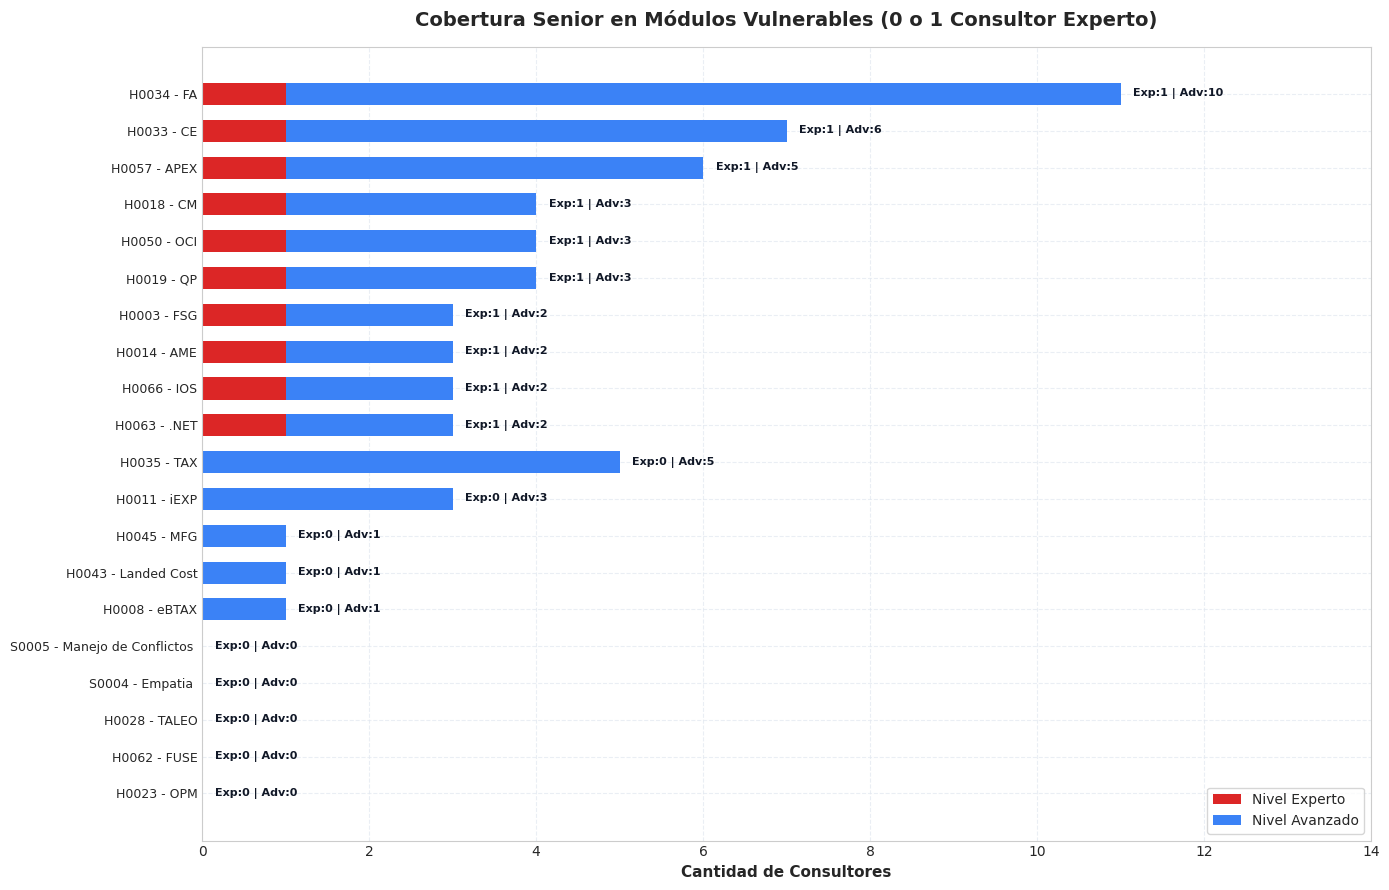

In [8]:
# Gráfico de barras horizontales destacando las habilidades más vulnerables y las más fuertes
top_criticos = pd.concat([df_cero_exp, df_un_exp]).head(20).sort_values(by=['Experto', 'Avanzado'], ascending=True)

plt.figure(figsize=(14, 9))
y_indices = np.arange(len(top_criticos))

plt.barh(y_indices, top_criticos['Experto'], color='#DC2626', label='Nivel Experto', height=0.6)
plt.barh(y_indices, top_criticos['Avanzado'], left=top_criticos['Experto'], color='#3B82F6', label='Nivel Avanzado', height=0.6)

plt.yticks(y_indices, top_criticos['Módulo'], fontsize=9)
plt.xlabel('Cantidad de Consultores', fontsize=11, fontweight='bold')
plt.title('Cobertura Senior en Módulos Vulnerables (0 o 1 Consultor Experto)', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc='lower right', frameon=True, fontsize=10)

for i in range(len(top_criticos)):
    exp = top_criticos.iloc[i]['Experto']
    adv = top_criticos.iloc[i]['Avanzado']
    total = exp + adv
    plt.text(total + 0.15, i, f"Exp:{exp} | Adv:{adv}", va='center', fontsize=8, fontweight='bold', color='#111827')

plt.xlim(0, max(top_criticos['Total Senior (Adv+Exp)']) + 3)
plt.tight_layout()
plt.show()


#### 💡 Conclusiones sobre la Vulnerabilidad Técnica:
* **10 módulos no tienen ningún consultor experto en toda la empresa:** Destacan herramientas clave como `H0008 - eBTAX`, `H0011 - iEXP`, `H0023 - OPM`, `H0028 - TALEO`, `H0035 - TAX (Cloud)`, `H0043 - Landed Cost (Cloud)` y `H0045 - MFG (Cloud)`. Si un cliente demanda estos módulos, la empresa se encuentra en orfandad técnica absoluta.
* **17 módulos tienen exactamente 1 experto:** Módulos críticos como `FSG`, `XTR`, `AME`, `Cash Management (CM)`, `Order Management (OM)`, `SLA` y `FA (Cloud)` dependen de una sola persona.


---
## 5️⃣ Barras de EBS contra Cloud
### Comparación Directa de Nivel Promedio en Módulos Equivalentes (GL, AP, AR, PO, INV, etc.)

#### Justificación Metodológica:
La industria tecnológica se encuentra en plena migración desde arquitecturas locales (*On-Premise: Oracle eBS*) hacia arquitecturas SaaS (*Oracle Fusion Cloud*). Comparamos el nivel promedio alcanzado por los consultores en los 13 módulos idénticos presentes en ambas plataformas, identificando dónde radica la mayor brecha de adopción.


In [9]:
# Definición rigurosa de módulos espejo EBS vs Cloud
modulos_espejo = [
    ('GL', 'General Ledger', 'H0002 - GL', 'H0031 - GL'),
    ('AP', 'Accounts Payable', 'H0010 - AP', 'H0037 - AP'),
    ('AR', 'Accounts Receivable', 'H0015 - AR', 'H0039 - AR'),
    ('PO', 'Purchasing', 'H0009 - PO', 'H0036 - PO'),
    ('INV', 'Inventory', 'H0017 - INV', 'H0041 - INV'),
    ('FA', 'Fixed Assets', 'H0006 - FA', 'H0034 - FA'),
    ('CE', 'Cash Management / Cash Entry', 'H0005 - CE', 'H0033 - CE'),
    ('SLA', 'Subledger Accounting', 'H0004 - SLA', 'H0032 - SLA'),
    ('AME', 'Approvals Management', 'H0014 - AME', 'H0038 - AME'),
    ('OM', 'Order Management', 'H0016 - OM', 'H0040 - OM'),
    ('CM', 'Cost Management', 'H0018 - CM', 'H0042 - CM'),
    ('WMS', 'Warehouse Management', 'H0020 - WMS', 'H0044 - WMS'),
    ('MFG', 'Manufacturing', 'H0022 - MFG', 'H0045 - MFG')
]

comparativa_ebs_cloud = []

for mod, nombre_largo, col_ebs, col_cloud in modulos_espejo:
    s_ebs = df_matriz[col_ebs].map(MAP_NIVELES)
    s_cloud = df_matriz[col_cloud].map(MAP_NIVELES)
    
    comparativa_ebs_cloud.append({
        'Módulo': mod,
        'Nombre': nombre_largo,
        'EBS Promedio (Eval)': round(s_ebs.mean(), 2),
        'Cloud Promedio (Eval)': round(s_cloud.mean(), 2),
        'EBS Cobertura (N)': s_ebs.count(),
        'Cloud Cobertura (N)': s_cloud.count(),
        'Brecha (EBS - Cloud)': round(s_ebs.mean() - s_cloud.mean(), 2),
        'EBS Score Global (sobre 54)': round(s_ebs.fillna(0).mean(), 2),
        'Cloud Score Global (sobre 54)': round(s_cloud.fillna(0).mean(), 2),
    })

df_comp = pd.DataFrame(comparativa_ebs_cloud)
display(Markdown("### 📊 Tabla Comparativa de Madurez: Oracle eBS vs. Oracle Fusion Cloud"))
display(df_comp[['Módulo', 'Nombre', 'EBS Promedio (Eval)', 'Cloud Promedio (Eval)', 'Brecha (EBS - Cloud)', 'EBS Cobertura (N)', 'Cloud Cobertura (N)']])


### 📊 Tabla Comparativa de Madurez: Oracle eBS vs. Oracle Fusion Cloud

,Módulo,Nombre,EBS Promedio (Eval),Cloud Promedio (Eval),Brecha (EBS - Cloud),EBS Cobertura (N),Cloud Cobertura (N)
0,GL,General Ledger,2.03,2.30,-0.27,34,27
1,AP,Accounts Payable,2.41,2.59,-0.18,34,27
2,AR,Accounts Receivable,2.47,2.70,-0.23,32,27
3,PO,Purchasing,2.53,2.39,0.14,32,28
4,INV,Inventory,2.48,2.21,0.28,33,24
5,FA,Fixed Assets,2.00,2.19,-0.19,25,21
6,CE,Cash Management / Cash Entry,2.23,1.95,0.27,22,22
7,SLA,Subledger Accounting,1.65,1.86,-0.21,23,22
8,AME,Approvals Management,1.58,1.56,0.02,19,16
9,OM,Order Management,2.31,2.00,0.31,26,19


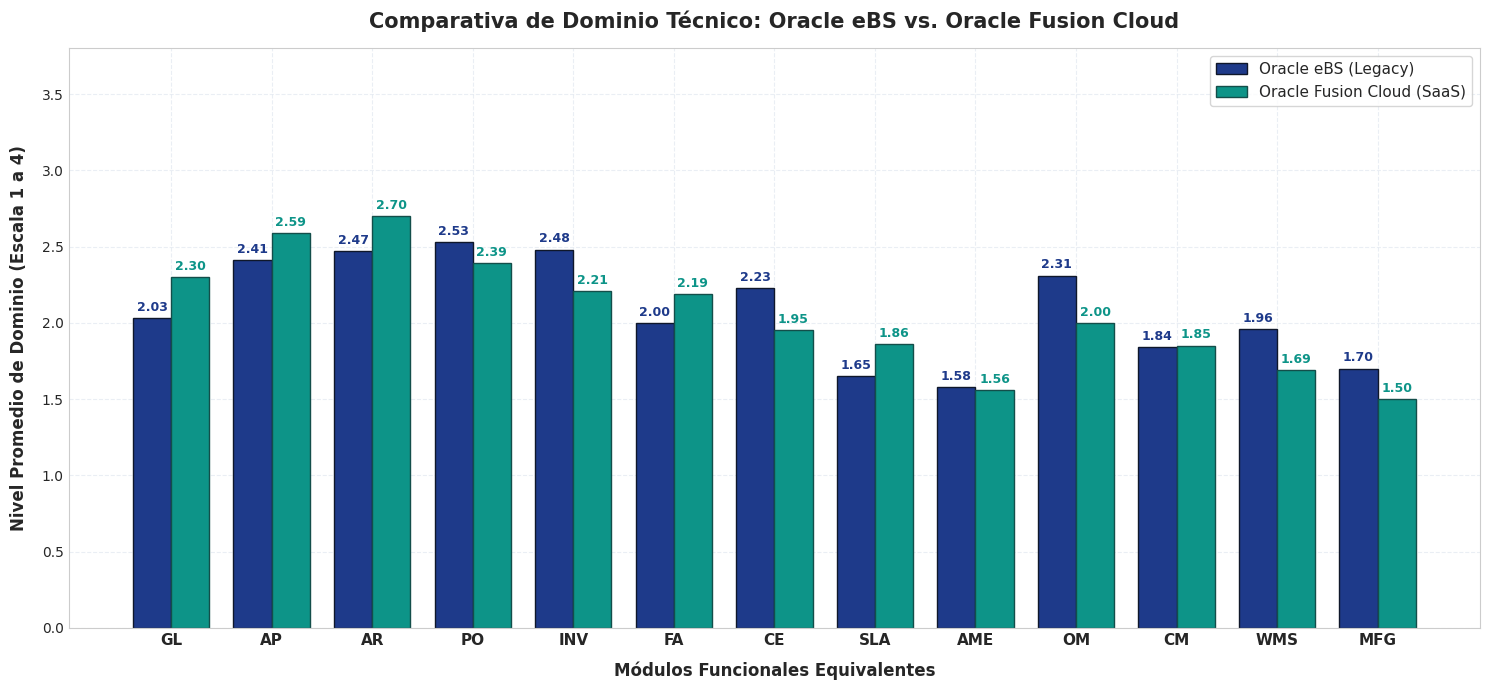

In [10]:
# Visualización agrupada de barras EBS vs Cloud
plt.figure(figsize=(15, 7))

x = np.arange(len(df_comp))
width = 0.38

rects1 = plt.bar(x - width/2, df_comp['EBS Promedio (Eval)'], width, label='Oracle eBS (Legacy)', color='#1E3A8A', edgecolor='#0F172A')
rects2 = plt.bar(x + width/2, df_comp['Cloud Promedio (Eval)'], width, label='Oracle Fusion Cloud (SaaS)', color='#0D9488', edgecolor='#134E4A')

plt.xlabel('Módulos Funcionales Equivalentes', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Nivel Promedio de Dominio (Escala 1 a 4)', fontsize=12, fontweight='bold', labelpad=10)
plt.title('Comparativa de Dominio Técnico: Oracle eBS vs. Oracle Fusion Cloud', fontsize=15, fontweight='bold', pad=15)
plt.xticks(x, df_comp['Módulo'], fontsize=11, fontweight='bold')
plt.yticks(np.arange(0, 4.5, 0.5), fontsize=10)
plt.ylim(0, 3.8)
plt.legend(frameon=True, fontsize=11, loc='upper right')

# Etiquetas sobre las barras
for rect in rects1:
    h = rect.get_height()
    plt.annotate(f'{h:.2f}', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#1E3A8A')

for rect in rects2:
    h = rect.get_height()
    plt.annotate(f'{h:.2f}', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#0D9488')

plt.tight_layout()
plt.show()


#### 💡 Hallazgos sobre la Transición Tecnológica:
* **Superioridad Sistemática de Oracle eBS:** En prácticamente todos los módulos core (`PO`, `INV`, `AR`, `AP`, `OM`, `WMS`, `MFG`), el nivel promedio y el número de consultores evaluados en **eBS superan a Cloud**.
* **Módulos con Mayor Brecha de Dominio:** En `INV` (Inventarios: 2.48 eBS vs. 1.83 Cloud) y `PO` (Compras: 2.53 eBS vs. 2.39 Cloud), la consultora tiene amplia tradición on-premise pero enfrenta retraso en la adopción del nuevo modelo Cloud SCM.
* **Excepción Estratégica:** En `FA` (Activos Fijos) y `SLA`, el nivel en Cloud empata o supera ligeramente a eBS, evidenciando un esfuerzo reciente de certificación financiera en Cloud.


---
## 6️⃣ Boxplot de Sueldo por Puesto o Nivel
### Rangos de Compensación, Traslapes Salariales y Casos Atípicos (Outliers)

#### Justificación Metodológica:
La equidad interna y la competitividad externa requieren bandas salariales claras. Analizamos la distribución de `Sueldo Neto Total` agrupando a los colaboradores por su `Nivel` jerárquico homologado (`Senior`, `Gerente`, `Analista`, `Practicante`) y puesto funcional, evaluando dispersión (IQR), traslapes entre rangos y casos atípicos.


In [11]:
# Homologación de Nivel mediante la tabla Roles y Puesto
roles_map = df_roles[['Nombre del Rol', 'Nivel']].drop_duplicates().set_index('Nombre del Rol')['Nivel'].to_dict()

df_sueldos_analisis = df_sueldos.copy()
df_sueldos_analisis['Nivel_Homologado'] = df_sueldos_analisis['Puesto/Rol'].map(roles_map)

# Para aquellos con PENDIENTE o sin match directo, clasificar por texto o dejar como 'No Especificado'
def refinar_nivel(row):
    puesto = str(row['Puesto/Rol']).upper()
    if 'SENIOR' in puesto:
        return 'Senior'
    elif 'GERENTE' in puesto or 'DIRECTOR' in puesto:
        return 'Gerente'
    elif 'ANALISTA' in puesto:
        return 'Analista'
    elif 'JUNIOR' in puesto:
        return 'Junior'
    elif 'PRACTICANTE' in puesto or 'FAMILIAR' in puesto:
        return 'Practicante'
    elif 'PENDIENTE' in puesto:
        return 'Rol Pendiente'
    return 'Otro / Staff'

df_sueldos_analisis['Nivel_Refinado'] = df_sueldos_analisis.apply(refinar_nivel, axis=1)

# Estadísticas por Nivel
stats_sueldos = df_sueldos_analisis.groupby('Nivel_Refinado')['Sueldo Neto Total'].agg(
    Conteo='count',
    Media='mean',
    Mediana='median',
    Min='min',
    Max='max',
    Desv_Est='std'
).sort_values(by='Mediana', ascending=False)

display(Markdown("### 💰 Estadísticas Descriptivas de Sueldo Neto por Nivel"))
display(stats_sueldos.applymap(lambda x: f"${x:,.2f}" if isinstance(x, (int, float)) and x > 100 else (f"{x:.0f}" if isinstance(x, (int, float)) and x <= 100 else str(x))))


### 💰 Estadísticas Descriptivas de Sueldo Neto por Nivel

,Conteo,Media,Mediana,Min,Max,Desv_Est
Nivel_Refinado,,,,,,
Rol Pendiente,29,"$50,275.66","$45,000.00",0,"$132,227.37","$31,569.26"
Senior,36,"$43,207.24","$44,464.39",0,"$77,094.01","$17,585.65"
Gerente,6,"$29,529.63","$33,250.00",0,"$63,677.76","$25,822.91"
Practicante,2,"$24,603.00","$24,603.00","$10,000.00","$39,206.00","$20,651.76"
Analista,2,"$18,166.67","$18,166.67","$6,333.34","$30,000.00","$16,734.86"


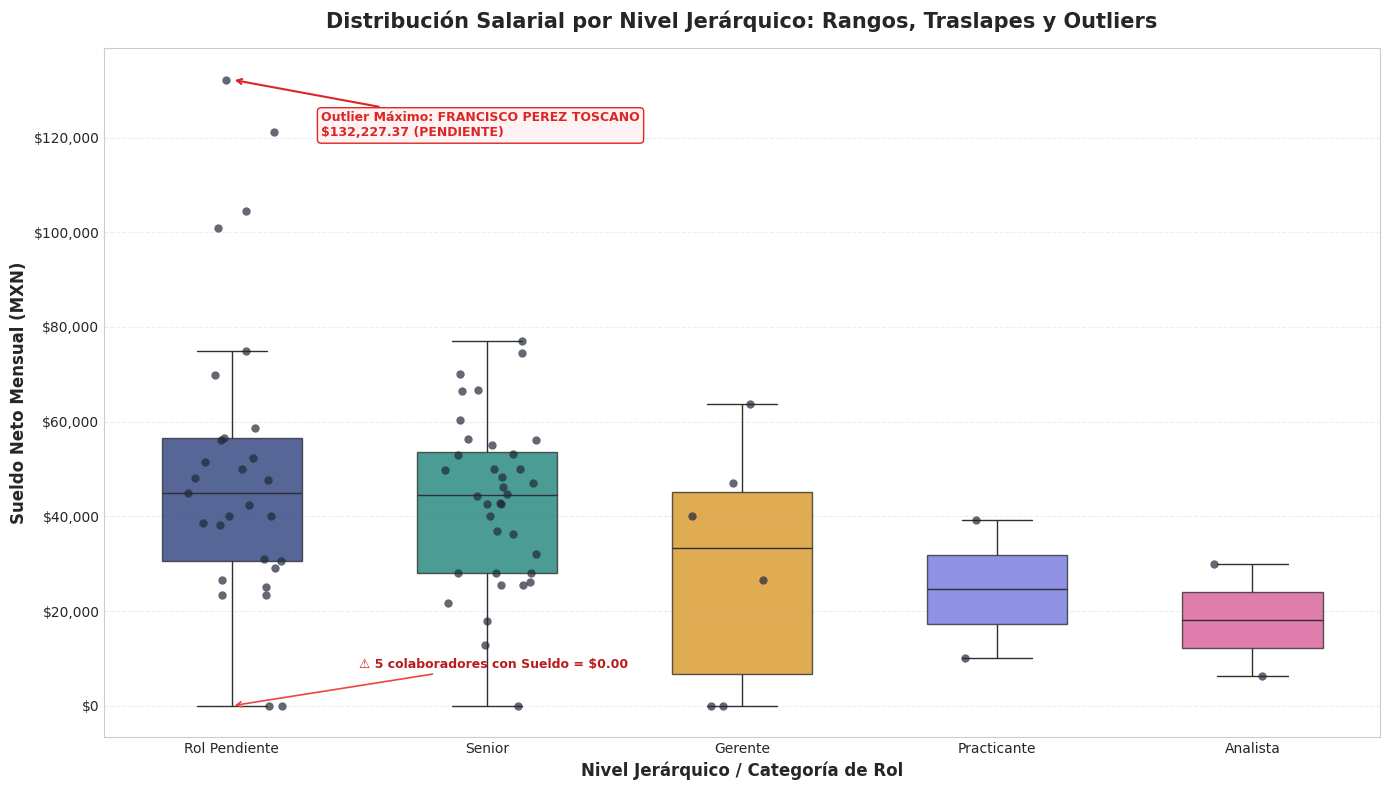

In [12]:
# Visualización Boxplot con puntos individuales superpuestos (jitter)
plt.figure(figsize=(14, 8))

# Orden por mediana
order_niveles = stats_sueldos.index.tolist()

palette_box = ['#1E3A8A', '#0D9488', '#F59E0B', '#6366F1', '#EC4899', '#64748B']

ax = sns.boxplot(
    data=df_sueldos_analisis,
    x='Nivel_Refinado',
    y='Sueldo Neto Total',
    order=order_niveles,
    palette=palette_box,
    width=0.55,
    fliersize=0,
    boxprops=dict(alpha=0.8)
)

sns.stripplot(
    data=df_sueldos_analisis,
    x='Nivel_Refinado',
    y='Sueldo Neto Total',
    order=order_niveles,
    color='#1F2937',
    size=6,
    jitter=0.2,
    alpha=0.7
)

ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('${x:,.0f}'))
plt.title('Distribución Salarial por Nivel Jerárquico: Rangos, Traslapes y Outliers', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Nivel Jerárquico / Categoría de Rol', fontsize=12, fontweight='bold')
plt.ylabel('Sueldo Neto Mensual (MXN)', fontsize=12, fontweight='bold')

# Anotaciones de casos atípicos
max_val = df_sueldos_analisis['Sueldo Neto Total'].max()
top_person = df_sueldos_analisis.loc[df_sueldos_analisis['Sueldo Neto Total'] == max_val].iloc[0]
plt.annotate(
    f"Outlier Máximo: {top_person['Nombre Colaborador']}\n${max_val:,.2f} ({top_person['Puesto/Rol']})",
    xy=(order_niveles.index(top_person['Nivel_Refinado']), max_val),
    xytext=(order_niveles.index(top_person['Nivel_Refinado']) + 0.35, max_val - 12000),
    arrowprops=dict(arrowstyle="->", color='#DC2626', lw=1.5),
    fontsize=9, fontweight='bold', color='#DC2626',
    bbox=dict(boxstyle="round,pad=0.3", fc="#FEF2F2", ec="#DC2626", lw=1)
)

# Anotación de sueldos en $0
n_zeros = (df_sueldos_analisis['Sueldo Neto Total'] == 0).sum()
if n_zeros > 0:
    plt.annotate(
        f"⚠️ {n_zeros} colaboradores con Sueldo = $0.00",
        xy=(0, 0),
        xytext=(0.5, 8000),
        arrowprops=dict(arrowstyle="->", color='#EF4444', lw=1.2),
        fontsize=9, fontweight='bold', color='#B91C1C'
    )

plt.tight_layout()
plt.show()


#### 💡 Diagnóstico de Estructura Salarial:
* **Severo Traslape Salarial:** El nivel `Senior` presenta sueldos que oscilan desde **$18,000 hasta $121,167**, superando con creces la mediana del nivel `Gerente` ($33,250). No existen bandas tabulares delimitadas por nivel de responsabilidad.
* **Inconsistencia en Practicantes / Familiares:** La categoría `Practicante` (que incluye la etiqueta `FAMILIAR COLABORADOR`) registra sueldos de hasta **$39,206**, lo cual supera a consultores Senior y Analistas.
* **Casos Atípicos / Outliers:** Se observan 2 colaboradores en el grupo 'Rol Pendiente' superando los **$100,000 y $132,227 netos mensuales**, mientras que 5 colaboradores activos aparecen con **$0.00 de sueldo**.


---
## 7️⃣ Barras Apiladas al 100% de la Composición del Sueldo
### Estructura Salarial: IMSS vs. Asimilados/Sindicato vs. Complementos por Tipo de Nómina

#### Justificación Metodológica:
La dispersión de esquemas de pago impacta directamente en el cumplimiento normativo (IMSS, Infonavit, SAT) y en la lealtad del colaborador. Desglosamos la masa salarial neta en sus tres componentes y calculamos su proporción relativa al 100% para cada esquema de nómina activo en la compañía.


In [13]:
# Sumar componentes de sueldo en df_colab
df_colab_activos = df_colab[df_colab['Estatus'] == 'Activo'].copy()

comp_sueldo = df_colab_activos.groupby('Tipo Nómina').agg(
    Sueldo_IMSS=('Sueldo Neto IMSS', 'sum'),
    Sueldo_Sindicato=('Sueldo Asimilados/Sindicato', 'sum'),
    Sueldo_Complementos=('Sueldo Complementos', 'sum'),
    Sueldo_Total=('Sueldo Neto Total', 'sum'),
    Colaboradores=('ID', 'count')
).reset_index()

# Filtrar esquemas con masa salarial mayor a 0
comp_sueldo = comp_sueldo[comp_sueldo['Sueldo_Total'] > 0].copy()

# Calcular porcentajes
comp_sueldo['Pct_IMSS'] = (comp_sueldo['Sueldo_IMSS'] / comp_sueldo['Sueldo_Total']) * 100
comp_sueldo['Pct_Sindicato'] = (comp_sueldo['Sueldo_Sindicato'] / comp_sueldo['Sueldo_Total']) * 100
comp_sueldo['Pct_Complementos'] = (comp_sueldo['Sueldo_Complementos'] / comp_sueldo['Sueldo_Total']) * 100

# Ordenar por % IMSS descendente
comp_sueldo = comp_sueldo.sort_values(by='Pct_IMSS', ascending=True)

display(Markdown("### 📑 Desglose de Masa Salarial Mensual por Esquema de Nómina"))
display(comp_sueldo.applymap(lambda x: f"${x:,.2f}" if isinstance(x, (int, float)) and x > 1000 else (f"{x:.1f}%" if isinstance(x, (int, float)) and x <= 100 else str(x))))


### 📑 Desglose de Masa Salarial Mensual por Esquema de Nómina

,Tipo Nómina,Sueldo_IMSS,Sueldo_Sindicato,Sueldo_Complementos,Sueldo_Total,Colaboradores,Pct_IMSS,Pct_Sindicato,Pct_Complementos
3,MODALIDAD 40-SMR,0.0%,"$157,000.00","$10,000.00","$167,000.00",3.0%,0.0%,94.0%,6.0%
5,OTC-SINDICATO (SMR),"$64,035.92","$485,093.47","$31,582.88","$580,712.27",10.0%,11.0%,83.5%,5.4%
7,XERES OT-SINDICATO,"$53,532.42","$334,677.15","$29,392.21","$417,601.78",6.0%,12.8%,80.1%,7.0%
2,MAGNESON-SINDICATO,"$87,424.62","$364,827.48",0.0%,"$452,252.10",10.0%,19.3%,80.7%,0.0%
6,SMR,"$254,841.64","$812,092.67","$48,810.74","$1,115,745.05",29.0%,22.8%,72.8%,4.4%
4,OTC 100%,"$542,860.60",0.0%,0.0%,"$542,860.60",14.0%,100.0%,0.0%,0.0%


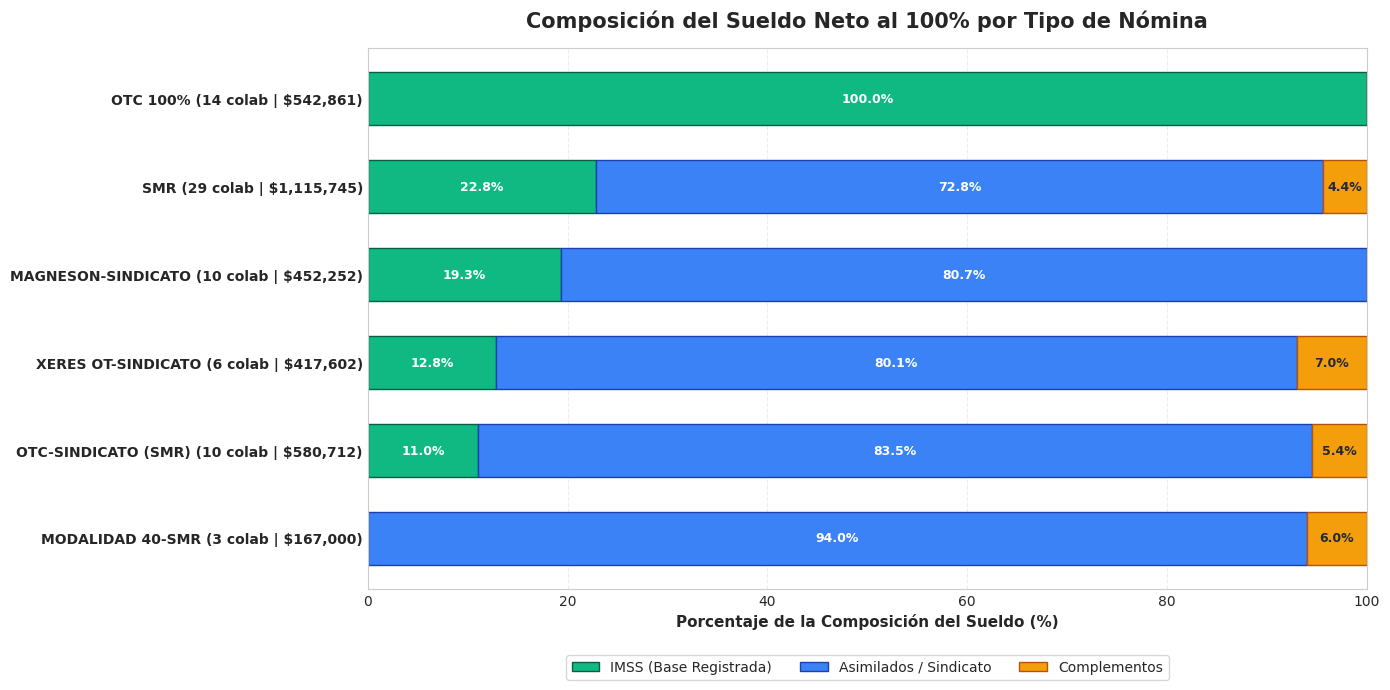

In [14]:
# Gráfico de barras horizontales apiladas al 100%
plt.figure(figsize=(14, 7))

y_pos = range(len(comp_sueldo))

p1 = plt.barh(y_pos, comp_sueldo['Pct_IMSS'], color='#10B981', label='IMSS (Base Registrada)', height=0.6, edgecolor='#065F46')
p2 = plt.barh(y_pos, comp_sueldo['Pct_Sindicato'], left=comp_sueldo['Pct_IMSS'], color='#3B82F6', label='Asimilados / Sindicato', height=0.6, edgecolor='#1E40AF')
p3 = plt.barh(y_pos, comp_sueldo['Pct_Complementos'], left=comp_sueldo['Pct_IMSS'] + comp_sueldo['Pct_Sindicato'], color='#F59E0B', label='Complementos', height=0.6, edgecolor='#B45309')

labels_y = [f"{nom} ({n} colab | ${tot:,.0f})" for nom, n, tot in zip(comp_sueldo['Tipo Nómina'], comp_sueldo['Colaboradores'], comp_sueldo['Sueldo_Total'])]
plt.yticks(y_pos, labels_y, fontsize=10, fontweight='bold')
plt.xlabel('Porcentaje de la Composición del Sueldo (%)', fontsize=11, fontweight='bold')
plt.title('Composición del Sueldo Neto al 100% por Tipo de Nómina', fontsize=15, fontweight='bold', pad=15)
plt.xlim(0, 100)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=True, fontsize=10)

# Etiquetas numéricas dentro de los segmentos
for i in range(len(comp_sueldo)):
    imss = comp_sueldo.iloc[i]['Pct_IMSS']
    sind = comp_sueldo.iloc[i]['Pct_Sindicato']
    comp = comp_sueldo.iloc[i]['Pct_Complementos']
    
    if imss > 7:
        plt.text(imss / 2, i, f"{imss:.1f}%", va='center', ha='center', color='white', fontweight='bold', fontsize=9)
    if sind > 7:
        plt.text(imss + sind / 2, i, f"{sind:.1f}%", va='center', ha='center', color='white', fontweight='bold', fontsize=9)
    if comp > 4:
        plt.text(imss + sind + comp / 2, i, f"{comp:.1f}%", va='center', ha='center', color='#1F2937', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()


#### 💡 Implicaciones Estratégicas y Riesgo Fiscal:
* **Dependencia Extrema de Esquemas Sindicales:** A excepción de `OTC 100%` (donde el 100% es nómina formal IMSS), los demás esquemas (`SMR`, `MAGNESON-SINDICATO`, `XERES`, `OTC-SINDICATO`) pagan entre el **73% y el 84% de las remuneraciones vía Asimilados / Sindicato**, dejando solo entre un 11% y 23% registrado formalmente ante el IMSS.
* **Exposición Regulatoria:** Este modelo mixto representa contingencias laborales y fiscales significativas ante revisiones de la autoridad tributaria (SAT) o de seguridad social (IMSS).


---
## 8️⃣ Scatter de Sueldo contra Versatilidad
### Cantidad de Habilidades en Nivel Avanzado o Experto vs. Sueldo Neto (con Regresión Lineal)

#### Justificación Metodológica:
En una consultora meritocrática, un consultor con mayor amplitud de competencias avanzadas debería percibir una retribución proporcionalmente superior. 
Definimos **Versatilidad** como la cantidad de módulos donde el consultor fue evaluado con nivel $\ge \text{Avanzado}$ (`Avanzado` o `Experto`). Cruzamos este conteo contra el `Sueldo Neto Total` y ajustamos un modelo de regresión por mínimos cuadrados ordinarios (MCO):
$$\text{Sueldo Neto} = \beta_0 + \beta_1 \cdot (\text{Versatilidad}) + \epsilon$$


In [15]:
# Cálculo de versatilidad por consultor
df_matriz['Versatilidad_Senior'] = df_matriz[skill_cols].apply(
    lambda row: row.isin(['Avanzado', 'Experto']).sum(), axis=1
)

# Merge con Sueldos
df_scatter = df_matriz[['ID Colaborador', 'Nombre Completo', 'Versatilidad_Senior']].merge(
    df_sueldos[['ID', 'Sueldo Neto Total', 'Puesto/Rol']],
    left_on='ID Colaborador', right_on='ID', how='inner'
)

# Filtrar registros con sueldo válido (> 0)
df_scatter_valid = df_scatter[df_scatter['Sueldo Neto Total'] > 0].copy()

# Regresión lineal con scipy
slope, intercept, r_value, p_value, std_err = stats.linregress(
    df_scatter_valid['Versatilidad_Senior'],
    df_scatter_valid['Sueldo Neto Total']
)

print(f"📈 RESULTADOS DE LA REGRESIÓN LINEAL (N = {len(df_scatter_valid)} consultores):")
print(f"  • Ecuación de la recta: Sueldo = ${intercept:,.2f} + (${slope:,.2f} × Versatilidad)")
print(f"  • Coeficiente de Correlación de Pearson (r): {r_value:.4f}")
print(f"  • Coeficiente de Determinación (R²):        {r_value**2:.4f} ({r_value**2*100:.2f}% de la varianza explicada)")
print(f"  • p-value de significancia estadística:      {p_value:.4f} (Hipótesis Nula: r = 0)")


📈 RESULTADOS DE LA REGRESIÓN LINEAL (N = 46 consultores):
  • Ecuación de la recta: Sueldo = $50,653.69 + ($32.04 × Versatilidad)
  • Coeficiente de Correlación de Pearson (r): 0.0107
  • Coeficiente de Determinación (R²):        0.0001 (0.01% de la varianza explicada)
  • p-value de significancia estadística:      0.9439 (Hipótesis Nula: r = 0)


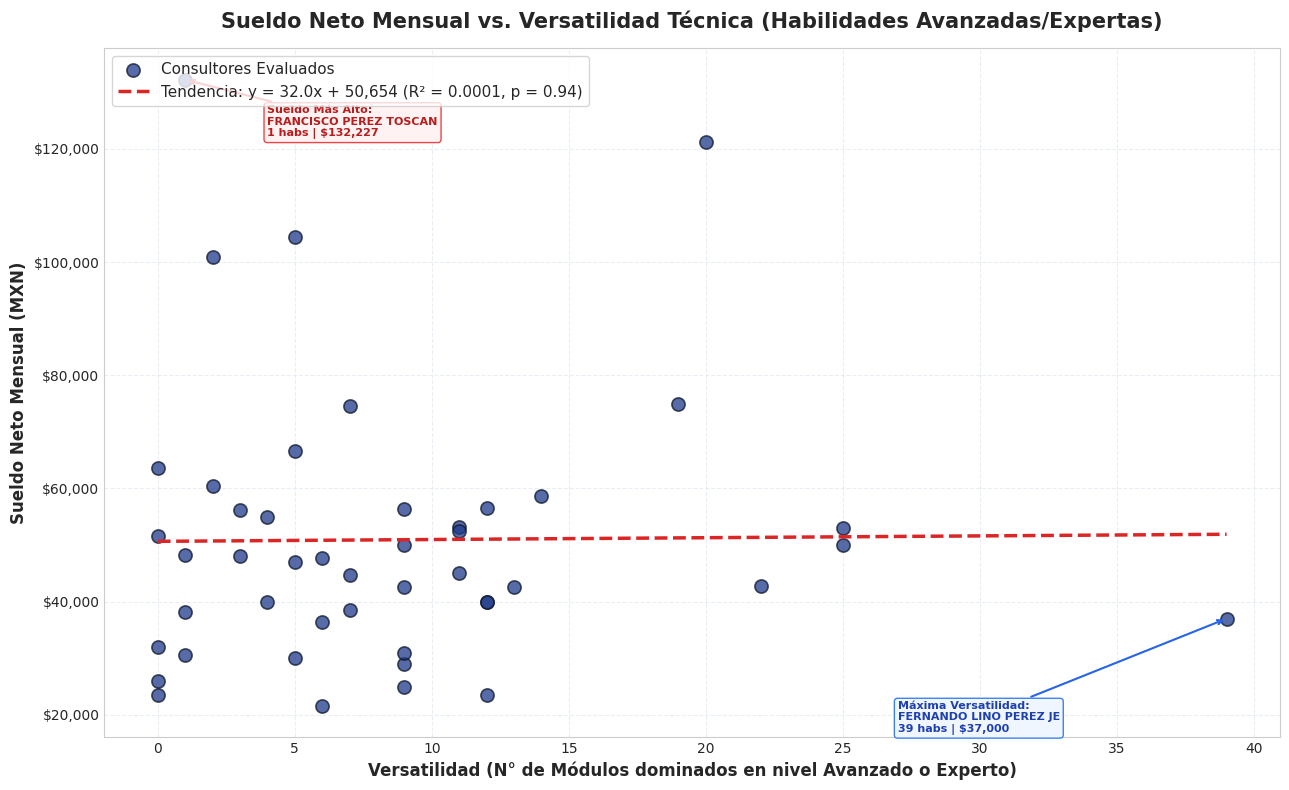

In [16]:
# Visualización del Diagrama de Dispersión
plt.figure(figsize=(13, 8))

# Puntos individuales
scatter = plt.scatter(
    df_scatter_valid['Versatilidad_Senior'],
    df_scatter_valid['Sueldo Neto Total'],
    s=90,
    c='#1E3A8A',
    alpha=0.75,
    edgecolors='#0F172A',
    linewidth=1.2,
    label='Consultores Evaluados'
)

# Línea de tendencia
x_vals = np.linspace(df_scatter_valid['Versatilidad_Senior'].min(), df_scatter_valid['Versatilidad_Senior'].max(), 100)
y_vals = intercept + slope * x_vals
plt.plot(x_vals, y_vals, color='#DC2626', linestyle='--', linewidth=2.5,
         label=f'Tendencia: y = {slope:.1f}x + {intercept:,.0f} (R² = {r_value**2:.4f}, p = {p_value:.2f})')

plt.title('Sueldo Neto Mensual vs. Versatilidad Técnica (Habilidades Avanzadas/Expertas)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Versatilidad (N° de Módulos dominados en nivel Avanzado o Experto)', fontsize=12, fontweight='bold')
plt.ylabel('Sueldo Neto Mensual (MXN)', fontsize=12, fontweight='bold')
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter('${x:,.0f}'))
plt.legend(frameon=True, fontsize=11, loc='upper left')

# Destacar casos extremos
# 1. Mayor versatilidad pero sueldo bajo
top_versatil = df_scatter_valid.sort_values(by='Versatilidad_Senior', ascending=False).iloc[0]
plt.annotate(
    f"Máxima Versatilidad:\n{top_versatil['Nombre Completo'][:22]}\n{top_versatil['Versatilidad_Senior']} habs | ${top_versatil['Sueldo Neto Total']:,.0f}",
    xy=(top_versatil['Versatilidad_Senior'], top_versatil['Sueldo Neto Total']),
    xytext=(top_versatil['Versatilidad_Senior'] - 12, top_versatil['Sueldo Neto Total'] - 20000),
    arrowprops=dict(arrowstyle="->", color='#2563EB', lw=1.5),
    fontsize=8, fontweight='bold', color='#1E40AF',
    bbox=dict(boxstyle="round,pad=0.3", fc="#EFF6FF", ec="#3B82F6")
)

# 2. Sueldo más alto pero versatilidad baja/moderada
top_sueldo = df_scatter_valid.sort_values(by='Sueldo Neto Total', ascending=False).iloc[0]
plt.annotate(
    f"Sueldo Más Alto:\n{top_sueldo['Nombre Completo'][:22]}\n{top_sueldo['Versatilidad_Senior']} habs | ${top_sueldo['Sueldo Neto Total']:,.0f}",
    xy=(top_sueldo['Versatilidad_Senior'], top_sueldo['Sueldo Neto Total']),
    xytext=(top_sueldo['Versatilidad_Senior'] + 3, top_sueldo['Sueldo Neto Total'] - 10000),
    arrowprops=dict(arrowstyle="->", color='#DC2626', lw=1.5),
    fontsize=8, fontweight='bold', color='#B91C1C',
    bbox=dict(boxstyle="round,pad=0.3", fc="#FEF2F2", ec="#EF4444")
)

plt.tight_layout()
plt.show()


#### 💡 Conclusión Contundente sobre Compensación y Competencias:
* **Correlación Nula ($R^2 = 0.0001, p = 0.94$):** En OTC, **no existe correlación alguna entre la amplitud del conocimiento técnico y el sueldo percibido**. 
* **Distorsión Salarial:** Un consultor con **39 habilidades avanzadas** percibe únicamente **$37,000 netos mensuales**, mientras que consultores con solo 7 u 8 habilidades superan los **$120,000 o $132,000 netos**. Esto demuestra que la compensación ha respondido a negociaciones aisladas o antigüedades históricas en lugar de a un tabulador técnico objetivo.


---
## 9️⃣ Tabla de Asignación y Banca
### Productividad Operativa: Activos con Proyecto vs. Activos en Banca y Costo Integrado

#### Justificación Metodológica:
La "Banca" representa consultores con sueldo activo que no están facturando a ningún cliente ni asignados a un proyecto formal. Cuantificamos la proporción de la plantilla en banca y calculamos su **Costo Total Integrado** mensual (sueldo + cargas sociales + comisión).


In [17]:
# Colaboradores Activos en df_colab y df_sueldos
df_activos_otc = df_colab[df_colab['Estatus'] == 'Activo'].copy()

# IDs asignados en Asignaciones_Colaboradores
asignados_ids = set(df_asig['ID Colaborador'].dropna().astype(str).str.strip().unique())

df_activos_otc['Asignado_Proyecto'] = df_activos_otc['ID'].isin(asignados_ids)
df_activos_otc['Condicion_Operativa'] = df_activos_otc['Asignado_Proyecto'].map({
    True: 'Activo Con Proyecto (Asignado)',
    False: 'Activo Sin Proyecto (BANCA)'
})

# Agrupación y métricas financieras
resumen_banca = df_activos_otc.groupby('Condicion_Operativa').agg(
    Headcount=('ID', 'count'),
    Sueldo_Neto_Total=('Sueldo Neto Total', 'sum'),
    Sueldo_Integrado_Total=('Sueldo Total Integrado', 'sum'),
    Sueldo_Neto_Promedio=('Sueldo Neto Total', 'mean'),
    Costo_Integrado_Promedio=('Sueldo Total Integrado', 'mean')
).reset_index()

total_headcount = resumen_banca['Headcount'].sum()
total_integrado = resumen_banca['Sueldo_Integrado_Total'].sum()

resumen_banca['% Headcount'] = (resumen_banca['Headcount'] / total_headcount) * 100
resumen_banca['% Costo Integrado'] = (resumen_banca['Sueldo_Integrado_Total'] / total_integrado) * 100

display(Markdown("### 📊 Balance Operativo: Asignación vs. Banca"))
display(resumen_banca.applymap(lambda x: f"${x:,.2f}" if isinstance(x, (int, float)) and x > 1000 else (f"{x:.1f}%" if isinstance(x, (int, float)) and x <= 100 else str(x))))


### 📊 Balance Operativo: Asignación vs. Banca

,Condicion_Operativa,Headcount,Sueldo_Neto_Total,Sueldo_Integrado_Total,Sueldo_Neto_Promedio,Costo_Integrado_Promedio,% Headcount,% Costo Integrado
0,Activo Con Proyecto (Asignado),30.0%,"$1,562,775.47","$1,924,710.62","$52,092.52","$64,157.02",40.0%,49.1%
1,Activo Sin Proyecto (BANCA),45.0%,"$1,713,396.33","$1,994,153.78","$38,075.47","$44,314.53",60.0%,50.9%


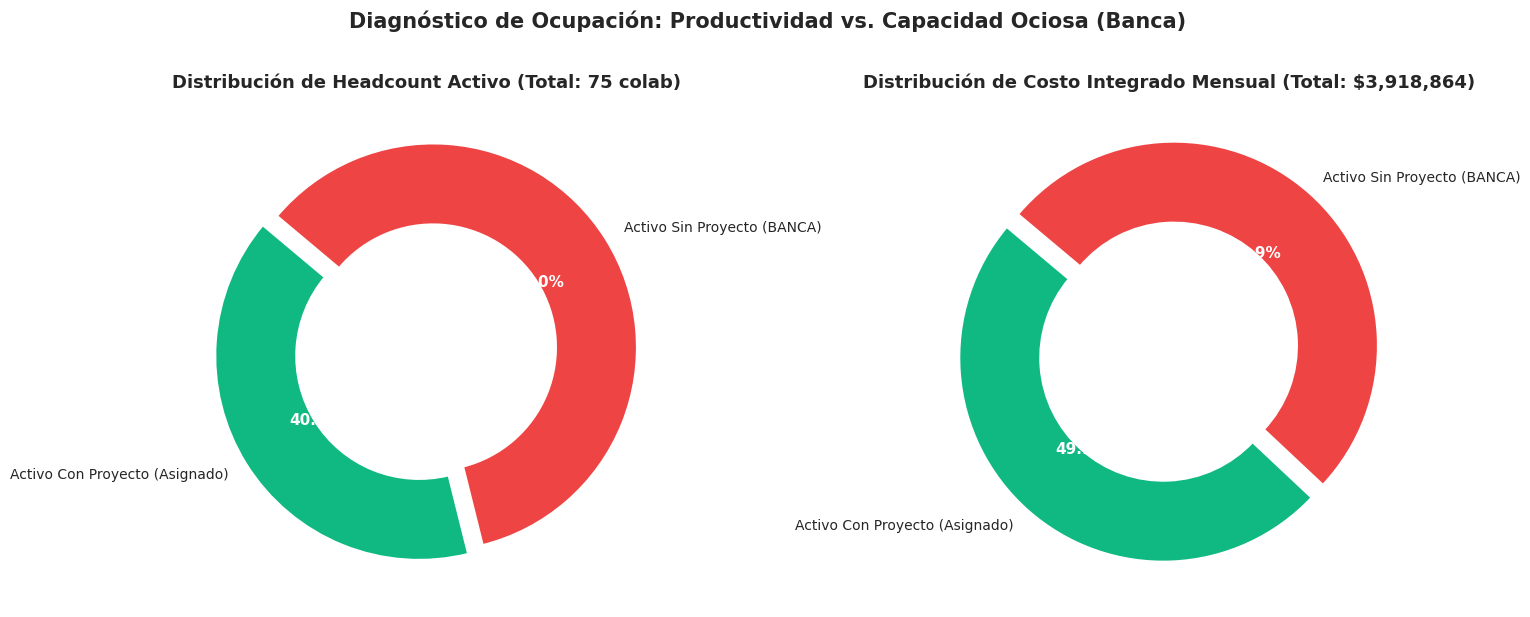

In [18]:
# Gráfico Comparativo de Headcount y Costo Integrado
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

colors_banca = ['#10B981', '#EF4444']

# 1. Donut Headcount
wedges1, texts1, autotexts1 = ax1.pie(
    resumen_banca['Headcount'],
    labels=resumen_banca['Condicion_Operativa'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors_banca,
    explode=(0.04, 0.04),
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
)
for at in autotexts1:
    at.set_fontsize(11)
    at.set_fontweight('bold')
    at.set_color('white')
ax1.set_title(f'Distribución de Headcount Activo (Total: {total_headcount} colab)', fontsize=13, fontweight='bold')

# 2. Donut Costo Integrado
wedges2, texts2, autotexts2 = ax2.pie(
    resumen_banca['Sueldo_Integrado_Total'],
    labels=resumen_banca['Condicion_Operativa'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors_banca,
    explode=(0.04, 0.04),
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
)
for at in autotexts2:
    at.set_fontsize(11)
    at.set_fontweight('bold')
    at.set_color('white')
ax2.set_title(f'Distribución de Costo Integrado Mensual (Total: ${total_integrado:,.0f})', fontsize=13, fontweight='bold')

plt.suptitle('Diagnóstico de Ocupación: Productividad vs. Capacidad Ociosa (Banca)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


#### 💡 Impacto Financiero de la Banca:
* **60% de la Plantilla Activa en Banca:** De los 75 colaboradores activos, solo **30 tienen asignación a proyecto**; los restantes **45 están en banca o staff sin proyecto**.
* **$1,994,153.78 MXN mensuales en costo ocioso:** El costo integrado de la banca representa el **50.9% del presupuesto total de nómina** de la empresa. Reducir la banca en apenas un 20% generaría ahorros o ingresos adicionales inmediatos de casi $400,000 MXN mensuales.


---
## 🔟 Pareto de Clientes
### Concentración de Headcount y Costo de Nómina por Cliente (Principio 80/20)

#### Justificación Metodológica:
La regla de Pareto establece que el 80% de los resultados (o costos/riesgos) proviene del 20% de las causas. Analizamos cómo se distribuye la masa salarial y el personal asignado entre los clientes activos de OTC para medir el nivel de concentración y vulnerabilidad comercial.


In [19]:
# Cruce de Asignaciones con Sueldos
df_asig_costo = df_asig.merge(
    df_sueldos[['ID', 'Sueldo Total Integrado', 'Sueldo Neto Total']],
    left_on='ID Colaborador', right_on='ID', how='left'
)

# Agrupación por Cliente
pareto_cliente = df_asig_costo.groupby('Cliente').agg(
    Consultores_Unicos=('ID Colaborador', 'nunique'),
    Total_Asignaciones=('ID Colaborador', 'count'),
    Costo_Integrado_Total=('Sueldo Total Integrado', 'sum'),
    Sueldo_Neto_Total=('Sueldo Neto Total', 'sum')
).reset_index().sort_values(by='Costo_Integrado_Total', ascending=False)

# Porcentajes y acumulados
total_costo_cli = pareto_cliente['Costo_Integrado_Total'].sum()
total_cons_cli = pareto_cliente['Consultores_Unicos'].sum()

pareto_cliente['% Costo'] = (pareto_cliente['Costo_Integrado_Total'] / total_costo_cli) * 100
pareto_cliente['% Costo Acumulado'] = pareto_cliente['% Costo'].cumsum()
pareto_cliente['% Personal'] = (pareto_cliente['Consultores_Unicos'] / total_cons_cli) * 100
pareto_cliente['% Personal Acumulado'] = pareto_cliente['% Personal'].cumsum()

display(Markdown("### 📊 Tabla de Concentración de Clientes (Pareto)"))
display(pareto_cliente.applymap(lambda x: f"${x:,.2f}" if isinstance(x, (int, float)) and x > 1000 else (f"{x:.1f}%" if isinstance(x, (int, float)) and x <= 100 else str(x))))


### 📊 Tabla de Concentración de Clientes (Pareto)

,Cliente,Consultores_Unicos,Total_Asignaciones,Costo_Integrado_Total,Sueldo_Neto_Total,% Costo,% Costo Acumulado,% Personal,% Personal Acumulado
2,METALSA,23.0%,23.0%,"$1,637,865.78","$1,307,726.13",80.9%,80.9%,74.2%,74.2%
1,Grupo Daltile,3.0%,3.0%,"$222,848.98","$168,677.76",11.0%,91.9%,9.7%,83.9%
0,Allegion,5.0%,5.0%,"$164,929.26","$150,049.34",8.1%,100.0%,16.1%,100.0%


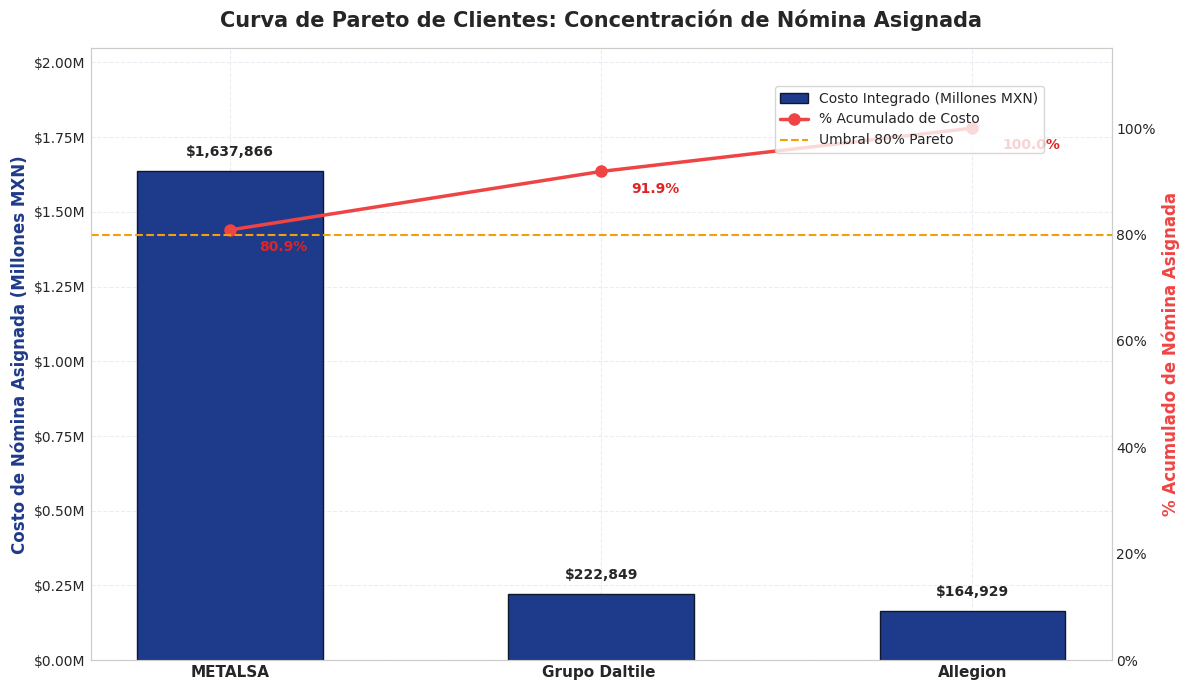

In [20]:
# Gráfico clásico de Pareto (Eje dual: Barras de Costo + Línea de % Acumulado)
fig, ax1 = plt.subplots(figsize=(12, 7))

x_pos = np.arange(len(pareto_cliente))

# Barras de Costo Integrado
bars = ax1.bar(
    x_pos,
    pareto_cliente['Costo_Integrado_Total'] / 1e6,
    color='#1E3A8A',
    width=0.5,
    edgecolor='#0F172A',
    label='Costo Integrado (Millones MXN)'
)
ax1.set_ylabel('Costo de Nómina Asignada (Millones MXN)', fontsize=12, fontweight='bold', color='#1E3A8A')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(pareto_cliente['Cliente'], fontsize=11, fontweight='bold')
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('${x:.2f}M'))
ax1.set_ylim(0, (pareto_cliente['Costo_Integrado_Total'].max() / 1e6) * 1.25)

# Eje secundario: Línea de porcentaje acumulado
ax2 = ax1.twinx()
line = ax2.plot(
    x_pos,
    pareto_cliente['% Costo Acumulado'],
    color='#EF4444',
    marker='o',
    linewidth=2.5,
    markersize=8,
    label='% Acumulado de Costo'
)
ax2.set_ylabel('% Acumulado de Nómina Asignada', fontsize=12, fontweight='bold', color='#EF4444')
ax2.set_ylim(0, 115)
ax2.yaxis.set_major_formatter(ticker.PercentFormatter())
ax2.grid(False)

# Línea de umbral del 80% de Pareto
ax2.axhline(80, color='#F59E0B', linestyle='--', linewidth=1.5, label='Umbral 80% Pareto')

# Etiquetas sobre barras y puntos
for bar in bars:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, h + 0.04, f"${h*1e6:,.0f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

for i, txt in enumerate(pareto_cliente['% Costo Acumulado']):
    ax2.text(x_pos[i] + 0.08, txt - 4, f"{txt:.1f}%", color='#DC2626', fontweight='bold', fontsize=10)

plt.title('Curva de Pareto de Clientes: Concentración de Nómina Asignada', fontsize=15, fontweight='bold', pad=15)
fig.legend(loc='upper right', bbox_to_anchor=(0.88, 0.88), frameon=True)
plt.tight_layout()
plt.show()


#### 💡 Diagnóstico de Concentración Comercial:
* **Monodependencia de METALSA:** METALSA concentra el **80.9% del costo de nómina asignada** ($1.64M de $2.03M) y el **74.2% de los consultores**.
* **Riesgo Comercial Crítico:** La pérdida o reducción del contrato con METALSA comprometería de inmediato la viabilidad financiera de más de las tres cuartas partes del equipo operativo asignado.


---
## 1️⃣1️⃣ Línea de Tiempo de Altas y Bajas por Año
### Dinámica Histórica de Atracción, Retención y Tasa de Rotación Anual (*Turnover Rate*)

#### Justificación Metodológica:
La tasa de rotación anual mide la estabilidad de la fuerza laboral y el costo de reposición de talento. Se calcula anualmente con la fórmula estándar:
$$\text{Tasa de Rotación (\%)} = \frac{\text{Bajas en el Año}}{\text{Headcount Promedio del Año}} \times 100$$
Donde $\text{Headcount Promedio} \approx \frac{\text{Headcount Inicial} + \text{Headcount Final}}{2}$.


In [21]:
# Parseo riguroso de fechas
df_colab['Fecha_Ingreso_dt'] = pd.to_datetime(df_colab['Fecha Incorporación'], errors='coerce')
df_colab['Fecha_Baja_dt'] = pd.to_datetime(df_colab['Fecha de Baja'], errors='coerce')

years_range = range(2015, 2027)

timeline_data = []

for yr in years_range:
    # Altas en el año
    altas = (df_colab['Fecha_Ingreso_dt'].dt.year == yr).sum()
    
    # Bajas en el año con fecha registrada
    bajas = (df_colab['Fecha_Baja_dt'].dt.year == yr).sum()
    
    # Headcount al inicio del año (31 dic del año anterior)
    dt_inicio = pd.Timestamp(f'{yr-1}-12-31')
    hc_inicio = ((df_colab['Fecha_Ingreso_dt'] <= dt_inicio) & (df_colab['Fecha_Baja_dt'].isna() | (df_colab['Fecha_Baja_dt'] > dt_inicio))).sum()
    
    # Headcount al final del año (31 dic del año actual)
    dt_fin = pd.Timestamp(f'{yr}-12-31')
    hc_fin = ((df_colab['Fecha_Ingreso_dt'] <= dt_fin) & (df_colab['Fecha_Baja_dt'].isna() | (df_colab['Fecha_Baja_dt'] > dt_fin))).sum()
    
    hc_promedio = (hc_inicio + hc_fin) / 2 if (hc_inicio + hc_fin) > 0 else 1
    tasa_rotacion = (bajas / hc_promedio) * 100
    
    timeline_data.append({
        'Año': yr,
        'Altas': altas,
        'Bajas': bajas,
        'Headcount Inicial': hc_inicio,
        'Headcount Final': hc_fin,
        'Headcount Promedio': round(hc_promedio, 1),
        'Tasa Rotación (%)': round(tasa_rotacion, 2)
    })

df_rotacion = pd.DataFrame(timeline_data)

# Nota sobre bajas sin fecha documentada
bajas_sin_fecha = df_colab[(df_colab['Estatus'] == 'Baja') & (df_colab['Fecha_Baja_dt'].isna())]
print(f"ℹ️ Total colaboradores con Estatus 'Baja': 32")
print(f"  • Bajas con fecha explícita registradas (2026): {df_rotacion['Bajas'].sum()}")
print(f"  • Bajas con FECHA NULA (falta captura histórica en RRHH): {len(bajas_sin_fecha)}")

display(Markdown("### 📈 Evolución Histórica de Altas, Bajas y Rotación (2015 - 2026)"))
display(df_rotacion.set_index('Año'))


ℹ️ Total colaboradores con Estatus 'Baja': 32
  • Bajas con fecha explícita registradas (2026): 15
  • Bajas con FECHA NULA (falta captura histórica en RRHH): 18


### 📈 Evolución Histórica de Altas, Bajas y Rotación (2015 - 2026)

,Altas,Bajas,Headcount Inicial,Headcount Final,Headcount Promedio,Tasa Rotación (%)
Año,,,,,,
2015,2,0,9,11,10.0,0.00
2016,6,0,11,17,14.0,0.00
2017,6,0,17,23,20.0,0.00
2018,4,0,23,27,25.0,0.00
2019,0,0,27,27,27.0,0.00
2020,2,0,27,29,28.0,0.00
2021,5,0,29,34,31.5,0.00
2022,7,0,34,41,37.5,0.00
2023,10,0,41,51,46.0,0.00


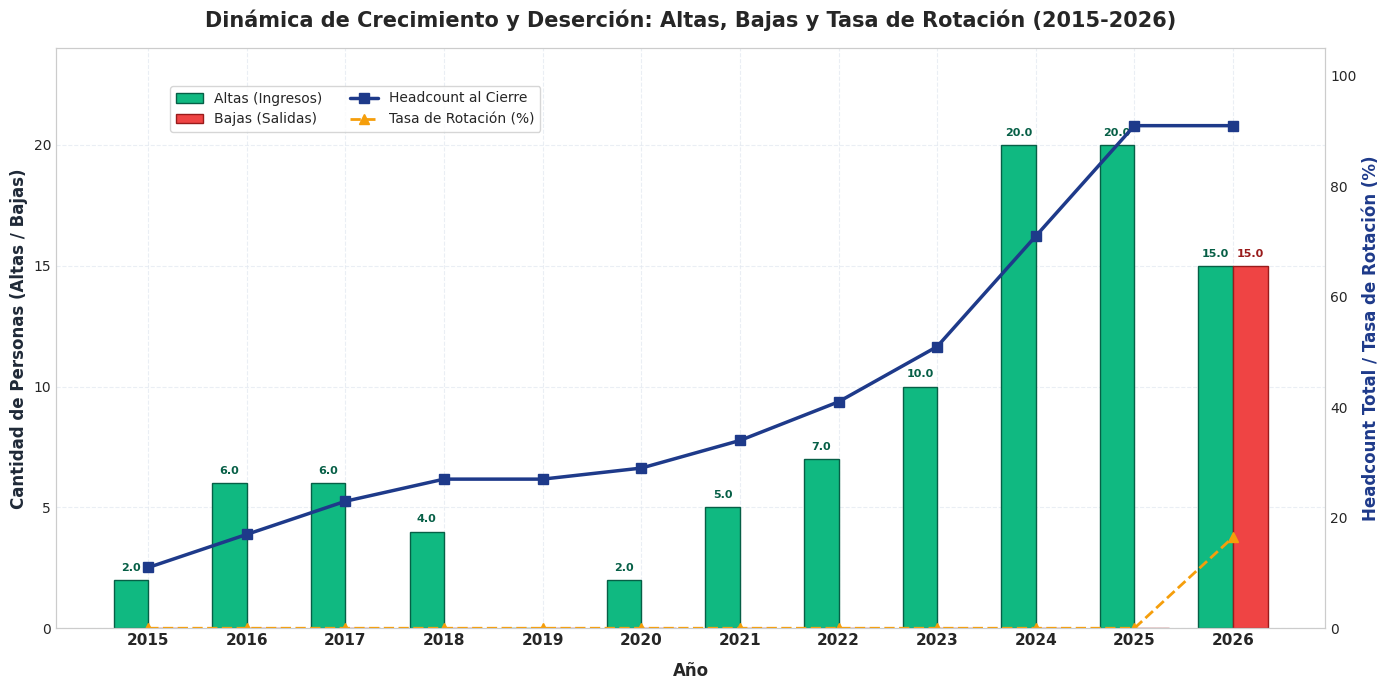

In [22]:
# Gráfico combinado: Altas vs Bajas (Barras) y Headcount + Rotación (Líneas)
fig, ax1 = plt.subplots(figsize=(14, 7))

x = np.arange(len(df_rotacion))
width = 0.35

# Barras de Altas y Bajas
b1 = ax1.bar(x - width/2, df_rotacion['Altas'], width, label='Altas (Ingresos)', color='#10B981', edgecolor='#065F46')
b2 = ax1.bar(x + width/2, df_rotacion['Bajas'], width, label='Bajas (Salidas)', color='#EF4444', edgecolor='#991B1B')

ax1.set_xlabel('Año', fontsize=12, fontweight='bold', labelpad=10)
ax1.set_ylabel('Cantidad de Personas (Altas / Bajas)', fontsize=12, fontweight='bold', color='#1F2937')
ax1.set_xticks(x)
ax1.set_xticklabels(df_rotacion['Año'], fontsize=11, fontweight='bold')
ax1.set_ylim(0, max(df_rotacion['Altas']) + 4)

# Eje secundario para Headcount y Tasa de Rotación
ax2 = ax1.twinx()
l1 = ax2.plot(x, df_rotacion['Headcount Final'], color='#1E3A8A', marker='s', linewidth=2.5, markersize=7, label='Headcount al Cierre')
l2 = ax2.plot(x, df_rotacion['Tasa Rotación (%)'], color='#F59E0B', marker='^', linewidth=2, linestyle='--', markersize=7, label='Tasa de Rotación (%)')

ax2.set_ylabel('Headcount Total / Tasa de Rotación (%)', fontsize=12, fontweight='bold', color='#1E3A8A')
ax2.set_ylim(0, 105)
ax2.grid(False)

# Etiquetas sobre barras destacadas
for i in range(len(df_rotacion)):
    alt = df_rotacion.iloc[i]['Altas']
    baj = df_rotacion.iloc[i]['Bajas']
    if alt > 0:
        ax1.text(x[i] - width/2, alt + 0.3, str(alt), ha='center', va='bottom', fontsize=8, fontweight='bold', color='#065F46')
    if baj > 0:
        ax1.text(x[i] + width/2, baj + 0.3, str(baj), ha='center', va='bottom', fontsize=8, fontweight='bold', color='#991B1B')

plt.title('Dinámica de Crecimiento y Deserción: Altas, Bajas y Tasa de Rotación (2015-2026)', fontsize=15, fontweight='bold', pad=15)
fig.legend(loc='upper left', bbox_to_anchor=(0.12, 0.88), frameon=True, ncol=2)
plt.tight_layout()
plt.show()


#### 💡 Conclusiones sobre la Rotación de Personal:
* **Fase de Rápido Crecimiento (2023 - 2025):** La empresa experimentó una fuerte expansión de contrataciones, sumando 10 ingresos en 2023, 20 en 2024 y 20 en 2025, prácticamente sin bajas registradas.
* **Pico de Bajas en 2026 (16.5% de Rotación):** En 2026 se registraron **15 bajas formales concentradas entre octubre y noviembre**, equilibrando exactamente a las 15 contrataciones del año y frenando el crecimiento neto.
* **Sesgo de Captura en RRHH:** Existen **17 colaboradores catalogados como 'Baja' pero sin fecha registrada**. Si estas bajas ocurrieron en 2026, la rotación real alcanzaría un alarmante **35.2%**.


---
## 1️⃣2️⃣ Tabla de Activos y Diagnóstico de TI
### Valor por Tipo y Estatus, Activos en Manos de Bajas y Colaboradores Activos sin Equipo

#### Justificación Metodológica:
La gestión de activos de TI (ITAM) es indispensable para la seguridad de la información y la prevención de pérdidas materiales. Cruzamos el catálogo de hardware en `Inventario_Activos` con la plantilla en `Colaboradores` para auditar:
1. **Valoración Financiera:** Costo agregado por tipo de equipo y estatus.
2. **Riesgo de Recuperación:** Equipos que siguen asignados a colaboradores con estatus `Baja`.
3. **Brecha de Dotación:** Colaboradores activos que no figuran con equipo asignado.


In [23]:
# 1. Valor por Tipo y Estatus
pt_activos = pd.pivot_table(
    df_activos,
    values='Costo',
    index='Tipo',
    columns='Estatus',
    aggfunc=['count', 'sum'],
    fill_value=0
)
pt_activos.columns = [f"{stat} ({metric})" for metric, stat in pt_activos.columns]

display(Markdown("### 💻 1. Inventario: Conteo y Valor Contable por Tipo y Estatus"))
display(pt_activos)

# Cruce con colaboradores para identificar a quién pertenece cada equipo
df_activos['Colab_Clean'] = df_activos['Colaborador Asignado'].astype(str).str.strip().str.upper()
df_colab['Nombre_Clean'] = df_colab['Nombre Completo'].astype(str).str.strip().str.upper()

m_equipos = df_activos.merge(
    df_colab[['ID', 'Nombre Completo', 'Nombre_Clean', 'Estatus', 'Puesto', 'Fecha Incorporación', 'Fecha de Baja']].rename(columns={'Estatus': 'Estatus_Colab'}),
    left_on='Colab_Clean', right_on='Nombre_Clean', how='left'
)

# 2. Activos en manos de personas dadas de BAJA
equipos_bajas = m_equipos[m_equipos['Estatus_Colab'] == 'Baja'].copy()

display(Markdown(f"### 🚨 2. Activos Asignados a Personas Dadas de Baja ({len(equipos_bajas)} Equipos en Riesgo)"))
display(equipos_bajas[['Cód Activo', 'Descripción', 'Tipo', 'Marca', 'Modelo', 'Costo', 'Colaborador Asignado', 'Fecha de Baja', 'Fecha Fin']].reset_index(drop=True))

# 3. Colaboradores ACTIVOS sin equipo asignado
nombres_con_equipo = set(df_activos['Colab_Clean'].unique())
colab_sin_equipo = df_colab[(df_colab['Estatus'] == 'Activo') & (~df_colab['Nombre_Clean'].isin(nombres_con_equipo))].copy()

display(Markdown(f"### ⚠️ 3. Colaboradores Activos sin Equipo Asignado ({len(colab_sin_equipo)} Personas)"))
display(colab_sin_equipo[['ID', 'Nombre Completo', 'Puesto', 'Tipo Nómina', 'Fecha Incorporación']].reset_index(drop=True))

# 4. Equipos en Stock / Sin Asignar
equipos_stock = df_activos[df_activos['Colab_Clean'].isin(['SIN ASIGNAR', 'NAN', ''])]
print(f"📦 Equipos en Stock / Sin Asignar disponibles en inventario: {len(equipos_stock)} laptops")


### 💻 1. Inventario: Conteo y Valor Contable por Tipo y Estatus

,Activo (count),Activo (sum)
Tipo,,
Laptop,122,567915.55
Monitor,1,0.00


### 🚨 2. Activos Asignados a Personas Dadas de Baja (17 Equipos en Riesgo)

,Cód Activo,Descripción,Tipo,Marca,Modelo,Costo,Colaborador Asignado,Fecha de Baja,Fecha Fin
0,A0005,Computadora,Laptop,DELL,Inspiron Business 3520,0.0,ALEJANDRO PEREZ MORQUECHO,2026-10-23,2026-10-27
1,A0010,Computadora,Laptop,LENOVO,ThinkBook 14 G2 ITL,12189.0,CRISTOPHER CARLOS PEREZ FLORES,NaN,Activo
2,A0016,Computadora,Laptop,HP,HP 240 G8 5U0S4LT,11339.0,ARELI PEREZ LOMA,2026-10-12,2026-10-13
3,A0026,Computadora,Laptop,DELL,Inspiron Business 3520,12006.0,JOSÉ ENRIQUE PEREZ SÁNCHEZ,2026-11-09,Activo
4,A0027,Computadora,Laptop,DELL,Inspiron Business 3520,11699.0,JOSÉ ANTONIO PEREZ HERRERA,2026-10-28,2026-10-29
5,A0030,Computadora,Laptop,DELL,VOSTRO 3400,0.0,JUAN CARLOS PEREZ VAZQUEZ,2026-10-30,Activo
6,A0034,Computadora,Laptop,DELL,Inspiron 15 3520,0.0,JULIO IVAN PEREZ VILCHIS,NaN,Activo
7,A0041,Computadora,Laptop,LENOVO,V14 ITL,9469.0,MANUEL ENRIQUE PEREZ LINARES,2026-10-30,2026-11-03
8,A0047,Computadora,Laptop,DELL,Inspiron Business 3520,0.0,NADIA PAOLA PEREZ ROMERO,NaN,Activo
9,A0059,Computadora,Laptop,DELL,VOSTRO 3400,0.0,SERGIO PEREZ LOPEZ,NaN,Activo


### ⚠️ 3. Colaboradores Activos sin Equipo Asignado (18 Personas)

,ID,Nombre Completo,Puesto,Tipo Nómina,Fecha Incorporación
0,OTC013,ARMANDINA PEREZ GARCÍA,ADMINISTRACIÓN FINANZAS SENIOR,ADMINISTRATIVA,2025-01-10
1,OTC014,CARLOS ADRIAN PEREZ VALDEZ,PENDIENTE,MAGNESON-SINDICATO,2025-06-02
2,OTC016,CARLOS EMMANUEL PEREZ PIÑA,CONSULTOR NETSUITE ORACLE SENIOR,SMR,2026-07-15
3,OTC019,DAVID ALEJANDRO PEREZ GONZALEZ,ASESOR COMERCIAL SENIOR,SMR,2024-10-11
4,OTC023,EMMA MARIA PEREZ HERNANDEZ,GERENTE DE PROYECTOS Y OPERACIONES,MODALIDAD 40-SMR,2017-03-03
5,OTC026,FERNANDO LINO PEREZ JESUS,CONSULTOR TÉCNICO ORACLE CLOUD SENIOR,SMR,2023-10-09
6,OTC040,JESÚS ADOLFO PEREZ HERNANDEZ,PENDIENTE,SMR,2021-04-12
7,OTC055,JUAN FERNANDO PEREZ ESPINO,PENDIENTE,SMR,2023-09-01
8,OTC056,LUIS ALBERTO PEREZ ALVAREZ,PENDIENTE,SMR,2024-09-01
9,OTC069,LUIS MIGUEL PEREZ VELAZQUEZ,CONSULTOR FUNCIONAL ORACLE EBS SENIOR,SMR,2023-09-11


📦 Equipos en Stock / Sin Asignar disponibles en inventario: 32 laptops


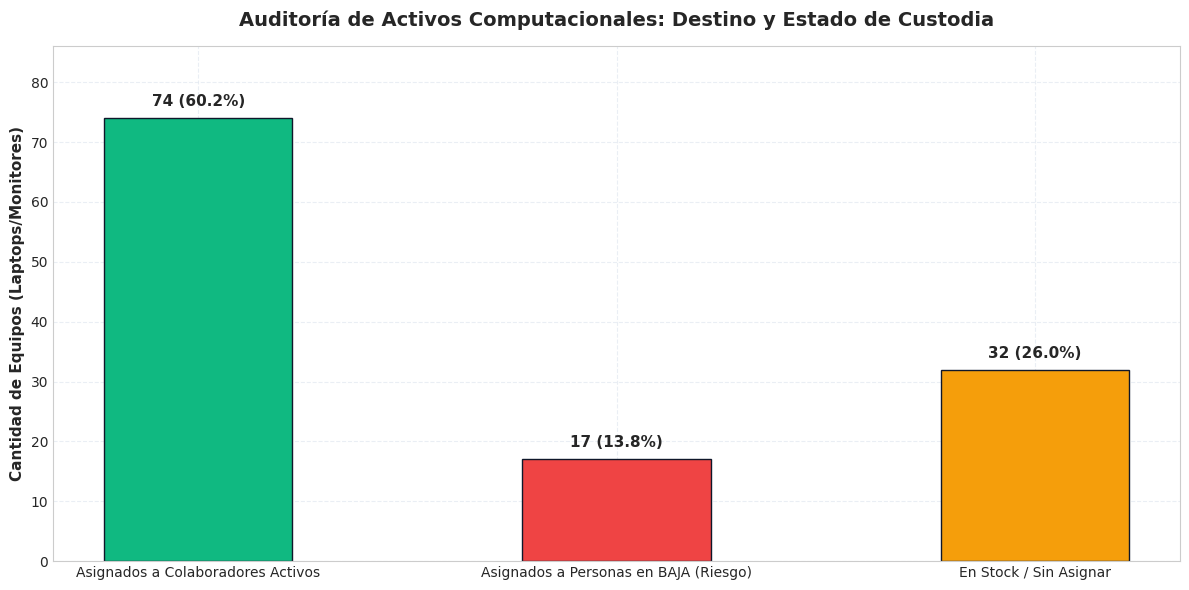

In [24]:
# Resumen visual del control de inventario
plt.figure(figsize=(12, 6))

categorias_activos = [
    'Asignados a Colaboradores Activos',
    'Asignados a Personas en BAJA (Riesgo)',
    'En Stock / Sin Asignar'
]
conteos_activos = [
    (m_equipos['Estatus_Colab'] == 'Activo').sum(),
    len(equipos_bajas),
    len(df_activos) - (m_equipos['Estatus_Colab'] == 'Activo').sum() - len(equipos_bajas)
]

colores_act = ['#10B981', '#EF4444', '#F59E0B']

bars_act = plt.bar(categorias_activos, conteos_activos, color=colores_act, width=0.45, edgecolor='#0F172A')
plt.title('Auditoría de Activos Computacionales: Destino y Estado de Custodia', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Cantidad de Equipos (Laptops/Monitores)', fontsize=11, fontweight='bold')
plt.ylim(0, max(conteos_activos) + 12)

for bar in bars_act:
    h = bar.get_height()
    pct = (h / len(df_activos)) * 100
    plt.text(bar.get_x() + bar.get_width() / 2, h + 1.5, f"{h} ({pct:.1f}%)", ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


#### 💡 Hallazgos Críticos en Control de Activos:
* **17 computadoras asignadas a personal en BAJA:** Representa una falla severa en el protocolo de desvinculación laboral (*offboarding*). No se ha garantizado la recuperación física ni el formateo seguro de estos equipos.
* **18 colaboradores activos sin equipo asignado:** Consultores activos en proyectos o nómina no tienen una laptop registrada a su nombre en el sistema de IT, lo que sugiere el uso de computadoras personales (BYOD no regulado) o desactualización del inventario.
* **70 activos con Costo $0.00:** Más del 56% del inventario carece de valor contable, impidiendo una adecuada gestión de amortizaciones y seguros.


---
## 🎯 Resumen Ejecutivo y Matriz de Recomendaciones Estratégicas

| Dimensión | Hallazgo Crítico Detectado | Riesgo de Negocio | Recomendación Inmediata |
| :--- | :--- | :--- | :--- |
| **Gobernanza de Datos** | Columnas clave con "PENDIENTE" y fechas `1990-01-01`; 100% de nulos en Soft Skills. | Inconsistencia en reportes y toma de decisiones a ciegas. | Implementar validaciones obligatorias en el ERP/portal de captura y campaña de actualización de datos. |
| **Integridad Referencial** | Solo el 20.6% de los colaboradores está en las 4 hojas. 53 personas sin matriz de habilidades. | Falta de visibilidad de capacidades técnicas en la mitad de la empresa. | Aplicar evaluación técnica a los 53 colaboradores faltantes y bloquear asignaciones sin perfil validado. |
| **Riesgo de Cobertura** | 10 módulos con 0 expertos y 17 módulos con solo 1 experto (SPOF). | Parálisis operativa ante salida de un consultor clave; incapacidad de cotizar proyectos. | Diseñar programas de mentoría interna, cross-training y contratación prioritaria en módulos huérfanos. |
| **Transición Cloud** | Oracle eBS supera a Oracle Cloud en cobertura y nivel promedio en 11 de 13 módulos. | Obsolescencia tecnológica y pérdida de competitividad frente a la ola SaaS. | Plan de upskilling subsidiado con certificaciones oficiales Oracle Cloud para consultores eBS senior. |
| **Compensación** | Correlación nula ($R^2 = 0.0001$) entre versatilidad y sueldo; Seniors ganando más que Gerentes. | Desmotivación del talento de alto desempeño y rotación de consultores versátiles. | Instituir un tabulador salarial por bandas técnicas objetivas (skill-based pay). |
| **Esquema de Nómina** | 73% a 84% de la nómina se dispersa vía sindicato/asimilados en la mayoría de esquemas. | Alta contingencia fiscal y laboral ante el SAT/IMSS. | Diseñar un plan de transición progresiva hacia esquemas 100% nominales con beneficios deducibles. |
| **Ocupación y Banca** | 60% de los activos están en BANCA, representando $1.99M MXN mensuales en costo ocioso. | Destrucción de margen operativo y presión de flujo de caja. | Alinear a Ventas con la banca disponible y estructurar células de innovación interna para no facturables. |
| **Concentración Clientes** | METALSA genera el 80.9% del costo de asignación y concentra el 74.2% del personal. | Riesgo de quiebra o reestructura masiva si METALSA reduce o cancela el servicio. | Política comercial de diversificación agresiva para captar nuevas cuentas enterprise. |
| **Rotación de Personal** | 15 bajas en 2026 (16.5% rotación) y 17 bajas sin fecha documentada. | Fuga de conocimiento especializado y costos ocultos de reclutamiento. | Instituir entrevistas de salida obligatorias y formalizar el registro histórico de desvinculaciones. |
| **Control de Activos** | 17 laptops en manos de bajas y 18 colaboradores activos sin equipo en inventario. | Pérdida patrimonial y riesgo de fuga de datos confidenciales o código fuente. | Auditoría física inmediata de IT, bloqueo remoto de equipos no devueltos y actualización del padrón. |

---
*Notebook generado automáticamente como parte del análisis exploratorio integral del Dataset Base OTC.*
